# 06 -- Megadrought Extensions: Recession, Aridity, Lag, and Long-Term Trends

Continues from `05_megadrought_analysis.ipynb`. Covers:
- Becca's ideas: recession coefficients, routing, basin aridity context
- Spatial map + basin-set-comparison-relevant top-20 table
- Long-term aridity trend + generalized (all-basin) long-term melt check
- Generalized (all-basin) deseasonalized lag analysis
- Lag-corrected fractions, mass-balance "bank account" test, and the
  melt/precip trend table that supports it (Noah)
- Peak water indicator, March->100% exclusion
- Ayala et al. replication check + MB decomposition (Noah)
- mu_star comparison and the seasonal-definition question (kept as
  sanity checks, not central to the notebook's flow)
- Methods-draft statistics (Ale) -- flagged for removal once done

**Basin-set selector (Cell 0):** same convention as `05` and
`04_regression_analysis.ipynb`. This notebook reloads the basin data
independently, so it can be run standalone -- just make sure
`BASIN_SET` matches whichever one you're comparing against in 05.


## Cell 0: Imports, paths, and basin-set selector

In [ ]:
import os, sys, pickle, calendar, warnings, json as jsonlib
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.colors import Normalize, to_hex
from matplotlib.cm import ScalarMappable
from scipy import stats
from scipy.stats import linregress
from scipy.optimize import curve_fit
warnings.filterwarnings('ignore')

sys.path.insert(0, '/Users/milliespencer/OGGM_CR2_Chile')
from basin_hierarchy_utils import compute_basin_hierarchy, build_containment_maps
from completeness_utils import assess_completeness

In [ ]:
# Basin-set selector: uncomment exactly ONE, then rerun top to bottom.
# Same convention as 04_regression_analysis.ipynb and basin_set_comparison.ipynb.

BASIN_SET = 'all_glacierized'   # nested sub-basins -- 03's output (~143 basins)
# BASIN_SET = 'grouped_main'    # geometrically top-level "main" basins -- 02's output (depth=0)
# BASIN_SET = 'leaf_only'       # smallest non-nested glacierized sub-basins -- derived on the fly

print(f'Basin set selected: {BASIN_SET}')

# Paths
BASE_PATH    = '/Users/milliespencer/Desktop/CR2_OGGM_Paper'
OUTPUT_ROOT  = f'{BASE_PATH}/Output'
CAMELS_FULL  = f'{BASE_PATH}/Full_CAMELS_all_basins/CAMELS_CL_v202201'
RGI_PATH     = f'{BASE_PATH}/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'
BOUNDS_PATH  = f'{CAMELS_FULL}/camels_cl_boundaries/camels_cl_boundaries.shp'
OUT_DIR_SUB  = f'{OUTPUT_ROOT}/all_chile_results_v2'
OUT_DIR_GRP  = f'{OUTPUT_ROOT}/grouped_basin_results'

# OUT_DIR kept for backward compatibility with cells below that reference
# f'{OUT_DIR}/...' directly (methods-stats / WA1-specific cells written
# before the basin-set selector existed). DROUGHT_DIR is the new
# basin-set-specific output folder for the core megadrought analysis.
OUT_DIR     = OUT_DIR_SUB
DROUGHT_DIR = f'{OUTPUT_ROOT}/megadrought_analysis/{BASIN_SET}'
os.makedirs(DROUGHT_DIR, exist_ok=True)

# Constants
YEARS         = list(range(2000, 2020))
MONTHS        = list(range(1, 13))
YEAR_OFFSET   = 1
WATER_DENSITY = 1000
CLUSTERS      = ['OT3','DA1','DA2','DA3','WA1','WA2','WA3','WA4','WA5','WA6']
DATASETS      = {'CR2MET': 'TC', 'ERA5': 'ERA5', 'CRU': 'CRU'}
DS_COLORS     = {'CR2MET': '#1f77b4', 'ERA5': '#ff7f0e', 'CRU': '#2ca02c'}
REGION_LABELS = {
    'OT3': 'Altiplano',     'DA1': 'Dry Andes N',
    'DA2': 'Dry Andes C',   'DA3': 'Dry Andes S',
    'WA1': 'Wet Andes N',   'WA2': 'Wet Andes C',
    'WA3': 'N Patagonia',   'WA4': 'S Patagonia',
    'WA5': 'Patagonia',     'WA6': 'Tierra del Fuego',
}
BASELINE     = list(range(2000, 2010))
DROUGHT_DEFS = {
    'Baseline (2000-2009)':  list(range(2000, 2010)),
    'Drought 1 (2010-2019)': list(range(2010, 2020)),
    'Drought 2 (2013-2019)': list(range(2013, 2020)),
    'Drought 3 (2015-2019)': list(range(2015, 2020)),
}
DROUGHT_COLORS = {
    'Baseline (2000-2009)':  '#2ecc71',
    'Drought 1 (2010-2019)': '#f39c12',
    'Drought 2 (2013-2019)': '#e67e22',
    'Drought 3 (2015-2019)': '#c0392b',
}
SUMMER = [12, 1, 2]
WINTER = [6, 7, 8]

def nc_path(dataset_name, cluster):
    tag = DATASETS[dataset_name]
    return (f'{OUTPUT_ROOT}/{dataset_name}/{cluster}/'
            f'run_output_2000_2019_hydro_{tag}_{cluster}.nc')

# Load the selected basin set -- same load_basin_set() logic as
# 04_regression_analysis.ipynb and basin_set_comparison.ipynb.

def _load_q_day():
    q_day = pd.read_csv(f'{CAMELS_FULL}/q_m3s_day.csv', parse_dates=['date'])
    return q_day[(q_day['year'] >= 1999) & (q_day['year'] <= 2019)].copy()

def _gauge_info_from_nested(nested_csv):
    info = {}
    for gauge_id, grp in nested_csv.groupby('gauge_id'):
        info[gauge_id] = {
            'gauge_name':       grp['gauge_name'].iloc[0],
            'rgi_ids':          grp['RGIId'].tolist(),
            'n_glaciers':       len(grp),
            'glacier_area_km2': grp['Area'].sum(),
            'basin_area_km2':   grp['area_km2'].iloc[0],
            'clusters':         sorted(grp['Cluster'].unique().tolist()),
            'cen_lat':          grp['CenLat'].mean(),
            'cen_lon':          grp['CenLon'].mean(),
        }
    return info

if BASIN_SET == 'all_glacierized':
    print('Loading RESULTS from pickle (all_glacierized / nested)...')
    with open(f'{OUT_DIR_SUB}/RESULTS.pkl', 'rb') as f:
        RESULTS = pickle.load(f)
    print(f'  RESULTS loaded: {len(RESULTS["CR2MET"])} gauges')

    nested_csv = pd.read_csv(f'{OUT_DIR_SUB}/spatial_join_nested.csv', dtype={'gauge_id': str})
    GAUGE_INFO = _gauge_info_from_nested(nested_csv)

    q_day = _load_q_day()
    gauges_in_results = set(RESULTS['CR2MET'].keys())
    GAUGE_INFO_FRAC = {}
    for gid, info in GAUGE_INFO.items():
        if gid not in gauges_in_results:
            continue
        comp = assess_completeness(q_day, gid, info['cen_lat'])
        if comp['passes']:
            GAUGE_INFO_FRAC[gid] = {**info, 'complete_years': comp['complete_years']}

    BASIN_SET_LABEL = f'All glacierized sub-basins (nested, n={len(GAUGE_INFO_FRAC)})'

elif BASIN_SET == 'grouped_main':
    print('Loading RESULTS_grouped from pickle (grouped_main / depth=0)...')
    with open(f'{OUT_DIR_GRP}/RESULTS_grouped.pkl', 'rb') as f:
        RESULTS = pickle.load(f)

    GAUGE_INFO_FRAC = {}
    for gid, res in RESULTS['CR2MET'].items():
        if res is None:
            continue
        GAUGE_INFO_FRAC[gid] = {
            'gauge_name':       res['gauge_name'],
            'clusters':         res['clusters'],
            'cen_lat':          res['cen_lat'],
            'glacier_area_km2': res['glacier_area_km2'],
            'basin_area_km2':   res['basin_area_km2'],
            'complete_years':   res['complete_years'],
            'rgi_ids':          [],
        }

    BASIN_SET_LABEL = f'Geometrically top-level "main" basins (depth=0, n={len(GAUGE_INFO_FRAC)})'

elif BASIN_SET == 'leaf_only':
    print('Loading RESULTS from pickle (leaf_only)...')
    with open(f'{OUT_DIR_SUB}/RESULTS.pkl', 'rb') as f:
        RESULTS = pickle.load(f)
    nested_csv = pd.read_csv(f'{OUT_DIR_SUB}/spatial_join_nested.csv', dtype={'gauge_id': str})
    GAUGE_INFO = _gauge_info_from_nested(nested_csv)
    glacier_area_by_gauge = nested_csv.groupby('gauge_id')['Area'].sum().to_dict()
    all_glacierized_ids = set(gid for gid, area in glacier_area_by_gauge.items() if area > 0)

    bounds_all = gpd.read_file(BOUNDS_PATH).to_crs(epsg=4326)
    bounds_all['gauge_id'] = bounds_all['gauge_id'].astype(str)
    bounds_utm = bounds_all.to_crs(epsg=32719)
    contained_map, container_map = build_containment_maps(bounds_utm, candidate_ids=all_glacierized_ids)

    leaf_ids = set()
    for gid in all_glacierized_ids:
        glacierized_children = [c for c in contained_map.get(gid, [])
                                 if glacier_area_by_gauge.get(c, 0) > 0]
        if len(glacierized_children) == 0:
            leaf_ids.add(gid)

    q_day = _load_q_day()
    gauges_in_results = set(RESULTS['CR2MET'].keys())
    GAUGE_INFO_FRAC = {}
    for gid in leaf_ids:
        if gid not in GAUGE_INFO or gid not in gauges_in_results:
            continue
        info = GAUGE_INFO[gid]
        comp = assess_completeness(q_day, gid, info['cen_lat'])
        if comp['passes']:
            GAUGE_INFO_FRAC[gid] = {**info, 'complete_years': comp['complete_years']}

    BASIN_SET_LABEL = f'Leaf-level glacierized sub-basins (n={len(GAUGE_INFO_FRAC)} of {len(leaf_ids)} total leaves)'

else:
    raise ValueError(f'Unknown BASIN_SET: {BASIN_SET!r}')

print(BASIN_SET_LABEL)
print(f'Outputs will be saved to: {DROUGHT_DIR}')
print()
print('Cell 0 complete')


Basin set selected: all_glacierized
Loading RESULTS from pickle (all_glacierized / nested)...
  RESULTS loaded: 143 gauges
All glacierized sub-basins (nested, n=143)
Outputs will be saved to: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/megadrought_analysis/all_glacierized

Cell 0 complete


## I. Load CAMELS-CL basin-average climate data

Basin-average monthly precipitation, temperature, tmax, tmin, and PET
from CAMELS-CL (CR2MET). Used to empirically validate drought period
definitions, diagnose precipitation- vs. temperature-driven drought, and
decompose the drivers of increased glacier fraction during drought.

In [19]:
print('Loading CAMELS-CL climate...')

def load_camels_mon(fname, value_name, year_range=(2000,2019)):
    df = pd.read_csv(f'{CAMELS_FULL}/{fname}')
    df = df[(df['year'] >= year_range[0]) &
            (df['year'] <= year_range[1])].copy()
    gauge_cols = [c for c in df.columns
                  if c not in ['date','year','month','day']]
    return df[['year','month'] + gauge_cols]

precip_df = load_camels_mon('precip_cr2met_mm_mon.csv',  'precip')
tmean_df  = load_camels_mon('tmean_cr2met_C_mon.csv',    'tmean')
tmax_df   = load_camels_mon('tmax_cr2met_C_mon.csv',     'tmax')
tmin_df   = load_camels_mon('tmin_cr2met_C_mon.csv',     'tmin')
pet_df    = load_camels_mon('pet_hargreaves_mm_mon.csv', 'pet')

print(f'Precip:  {precip_df.shape}')
print(f'Tmean:   {tmean_df.shape}')
print(f'PET:     {pet_df.shape}')
print('CAMELS-CL climate loaded')


Loading CAMELS-CL climate...
Precip:  (240, 518)
Tmean:   (240, 519)
PET:     (240, 518)
CAMELS-CL climate loaded


In [20]:
# Bounds and country borders -- needed by the spatial map cell below.
bounds = gpd.read_file(BOUNDS_PATH)
bounds['gauge_id'] = bounds['gauge_id'].astype(str)

try:
    world = gpd.read_file(
        'https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip')
    chile = world[world['NAME'] == 'Chile']
    arg   = world[world['NAME'] == 'Argentina']
    has_borders = True
except Exception:
    has_borders = False
    print('Country borders unavailable')

print(f'Bounds loaded: {len(bounds)} CAMELS basins')


Bounds loaded: 516 CAMELS basins


## Addressing Becca's ideas: recession coefficient & routing

Becca's suggestion: estimate a recession coefficient from the falling
limb of the CAMELS hydrograph for each basin, to (1) improve estimates
of how much water actually reaches streams, and (2) understand basin
storage dynamics -- how long water takes to move through other stores.
Also: contextualize glacier importance against basin aridity.

In [21]:
print('Loading daily streamflow and precipitation...')
q_day    = pd.read_csv(f'{CAMELS_FULL}/q_m3s_day.csv', parse_dates=['date'])
prec_day = pd.read_csv(f'{CAMELS_FULL}/precip_cr2met_mm_day.csv', parse_dates=['date'])

q_day    = q_day[(q_day['year'] >= 2000) & (q_day['year'] <= 2019)].reset_index(drop=True)
prec_day = prec_day[(prec_day['year'] >= 2000) & (prec_day['year'] <= 2019)].reset_index(drop=True)

print(f'Q daily:    {q_day.shape}')
print(f'Prec daily: {prec_day.shape}')

MIN_RECESSION_DAYS = 5
PREC_THRESHOLD_MM  = 1.0
MIN_Q_M3S          = 0.01

def exp_decay(t, q0, k):
    return q0 * np.exp(-k * t)

def compute_recession_k(gauge_id, q_series, prec_series):
    if gauge_id not in q_series.columns:
        return []
    if gauge_id not in prec_series.columns:
        prec = pd.Series(0, index=q_series.index)
    else:
        prec = prec_series[gauge_id]

    q = q_series[gauge_id].values
    p = prec.values
    k_vals = []

    i = 0
    while i < len(q) - MIN_RECESSION_DAYS:
        if (not np.isnan(q[i]) and q[i] > MIN_Q_M3S and
                not np.isnan(q[i+1]) and q[i+1] < q[i]):
            j = i + 1
            while (j < len(q) and not np.isnan(q[j]) and q[j] < q[j-1] and
                   q[j] > MIN_Q_M3S and (np.isnan(p[j]) or p[j] < PREC_THRESHOLD_MM)):
                j += 1
            seg_len = j - i
            if seg_len >= MIN_RECESSION_DAYS:
                t_seg = np.arange(seg_len, dtype=float)
                q_seg = q[i:j]
                try:
                    popt, _ = curve_fit(exp_decay, t_seg, q_seg, p0=[q_seg[0], 0.05],
                                        bounds=([0, 1e-6], [1e6, 2.0]), maxfev=2000)
                    k_vals.append(popt[1])
                except Exception:
                    pass
            i = j
        else:
            i += 1
    return k_vals

print('Computing recession coefficients for all gauges...')

recession_results = []
for gauge_id in GAUGE_INFO_FRAC:
    gid = str(gauge_id)
    k_vals = compute_recession_k(gid, q_day, prec_day)
    if len(k_vals) == 0:
        continue

    info = GAUGE_INFO_FRAC[gauge_id]
    recession_results.append({
        'gauge_id': gauge_id, 'gauge_name': info['gauge_name'][:35],
        'lat': info['cen_lat'], 'cluster': info['clusters'][0],
        'glacier_area_km2': info['glacier_area_km2'],
        'basin_area_km2': info.get('basin_area_km2', np.nan),
        'glac_pct': info['glacier_area_km2'] / info.get('basin_area_km2', np.nan) * 100
                    if info.get('basin_area_km2') else np.nan,
        'k_median': np.median(k_vals), 'k_mean': np.mean(k_vals),
        'k_std': np.std(k_vals), 'n_recession_segs': len(k_vals),
    })

df_recession = pd.DataFrame(recession_results)
print(f'Recession coefficients computed: {len(df_recession)} gauges')
print(f'Median k across all gauges: {df_recession["k_median"].median():.4f} day-1')
print('Median k by cluster:')
print(df_recession.groupby('cluster')['k_median'].median().round(4).to_string())


Loading daily streamflow and precipitation...
Q daily:    (7305, 520)
Prec daily: (7305, 520)
Computing recession coefficients for all gauges...
Recession coefficients computed: 143 gauges
Median k across all gauges: 0.0520 day-1
Median k by cluster:
cluster
DA1    0.0363
DA2    0.0604
DA3    0.0679
OT3    0.0388
WA1    0.0554
WA2    0.0619
WA3    0.0498
WA4    0.0792
WA6    0.1315


Correlations between computed k and CAMELS-CL proxy metrics:

  k vs Baseflow index (expect: k neg corr): r=-0.646  p=6.238e-09  ***
  k vs Slope FDC (expect: k pos corr)     : r=+0.442  p=2.308e-04  ***
  k vs Q5 low flow (expect: k neg corr)   : r=-0.236  p=5.873e-02  ns
  k vs Half-flow date (expect: k neg corr): r=+0.038  p=7.060e-01  ns


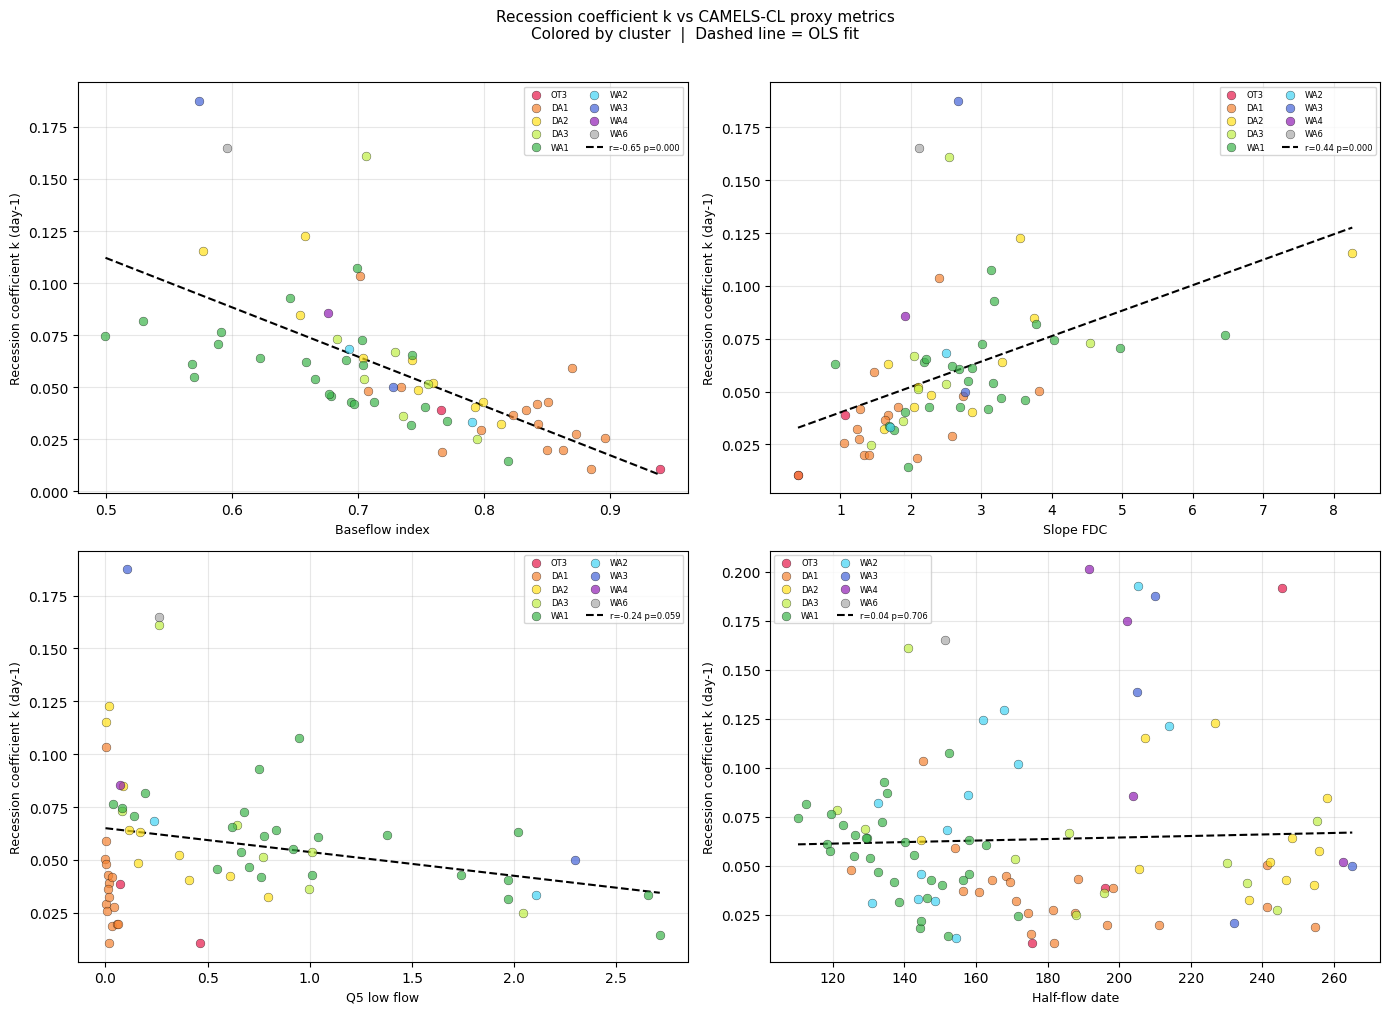

Recession coefficient and proxy metrics by cluster:
Cluster k_median   BFI      slope_fdc  hfd_mean   n
-------------------------------------------------------
OT3        0.0388    0.853      0.732      196.0   3
DA1        0.0363    0.843      1.548      175.3  22
DA2        0.0604    0.745      2.574      242.2  12
DA3        0.0679    0.729      2.103      188.1  16
WA1        0.0554    0.685      2.834      137.2  44
WA2        0.0619    0.742      2.096      154.5  30
WA3        0.0498    0.651      2.716      221.0   7
WA4        0.0792    0.676      1.916      203.0   7
WA6        0.1315    0.596      2.118      151.2   2


In [22]:
attrs = pd.read_csv(f'{CAMELS_FULL}/catchment_attributes.csv', dtype={'gauge_id': str})
proxy_cols = ['gauge_id', 'baseflow_index_1979_2010', 'slope_fdc_1979_2010',
              'Q5_1979_2010', 'Q95_1979_2010', 'hfd_mean']
attrs_sub = attrs[proxy_cols].copy()

df_rec_full = df_recession.merge(attrs_sub, on='gauge_id', how='left')

print('Correlations between computed k and CAMELS-CL proxy metrics:')
print()
proxy_vars = {
    'baseflow_index_1979_2010': 'Baseflow index (expect: k neg corr)',
    'slope_fdc_1979_2010':      'Slope FDC (expect: k pos corr)',
    'Q5_1979_2010':             'Q5 low flow (expect: k neg corr)',
    'hfd_mean':                 'Half-flow date (expect: k neg corr)',
}

for col, label in proxy_vars.items():
    sub = df_rec_full[['k_median', col]].dropna()
    if len(sub) < 5:
        continue
    r, p = stats.pearsonr(sub['k_median'], sub[col])
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f'  k vs {label[:35]:35s}: r={r:+.3f}  p={p:.3e}  {sig}')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes_flat = axes.flatten()

cluster_colors_map = {
    'OT3':'#e6194b', 'DA1':'#f58231', 'DA2':'#ffe119', 'DA3':'#bfef45',
    'WA1':'#3cb44b', 'WA2':'#42d4f4', 'WA3':'#4363d8', 'WA4':'#911eb4', 'WA6':'#a9a9a9'
}

for ax, (col, label) in zip(axes_flat, proxy_vars.items()):
    for cl in CLUSTERS:
        grp = df_rec_full[df_rec_full['cluster'] == cl]
        if len(grp) == 0:
            continue
        ax.scatter(grp[col], grp['k_median'], c=cluster_colors_map.get(cl, '#888888'),
                   s=40, alpha=0.7, edgecolors='k', lw=0.3, label=cl, zorder=3)

    sub = df_rec_full[['k_median', col]].dropna()
    if len(sub) > 5:
        slope, intercept, r, p, _ = stats.linregress(sub[col], sub['k_median'])
        xfit = np.linspace(sub[col].min(), sub[col].max(), 100)
        ax.plot(xfit, slope*xfit + intercept, 'k--', lw=1.5, label=f'r={r:.2f} p={p:.3f}')

    ax.set_xlabel(label.split('(')[0].strip(), fontsize=9)
    ax.set_ylabel('Recession coefficient k (day-1)', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=6, ncol=2)

fig.suptitle('Recession coefficient k vs CAMELS-CL proxy metrics\nColored by cluster  |  Dashed line = OLS fit',
             fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/recession_k_vs_proxies.png', dpi=150, bbox_inches='tight')
plt.show()

print('Recession coefficient and proxy metrics by cluster:')
print(f'{"Cluster":6s} {"k_median":10s} {"BFI":8s} {"slope_fdc":10s} {"hfd_mean":10s} {"n"}')
print('-' * 55)
for cl in CLUSTERS:
    grp = df_rec_full[df_rec_full['cluster'] == cl]
    if len(grp) == 0:
        continue
    print(f'{cl:6s} {grp["k_median"].median():10.4f} '
          f'{grp["baseflow_index_1979_2010"].median():8.3f} '
          f'{grp["slope_fdc_1979_2010"].median():10.3f} '
          f'{grp["hfd_mean"].median():10.1f} {len(grp):3d}')


**Note:** the cells below reference `per_basin_regression_partA_CR2MET.csv`
and `lag_results_CR2MET.csv` at legacy paths (`{OUT_DIR}/regression/...`,
`{OUT_DIR}/lag_analysis/...`) from before the notebook 04 rebuild. If
those files don't exist at those paths, update to point at
`04_regression_analysis.ipynb`'s `REG_DIR` output instead -- both cells
already guard with `os.path.exists()` and print a clear message if the
file isn't found.

Regression results loaded: 143 basins
Lag results loaded: 143 gauges
Key correlations with recession coefficient k:

  k vs beta_glacier (regression coef)     : r=-0.128  p=1.270e-01  ns
  k vs Per-basin R2                       : r=+0.008  p=9.221e-01  ns
  k vs Glacier % of basin                 : r=+0.006  p=9.389e-01  ns
  k vs Glacier area (km2)                 : r=-0.192  p=2.181e-02  *
  k vs Best lag (months)                  : r=+0.163  p=5.188e-02  ns


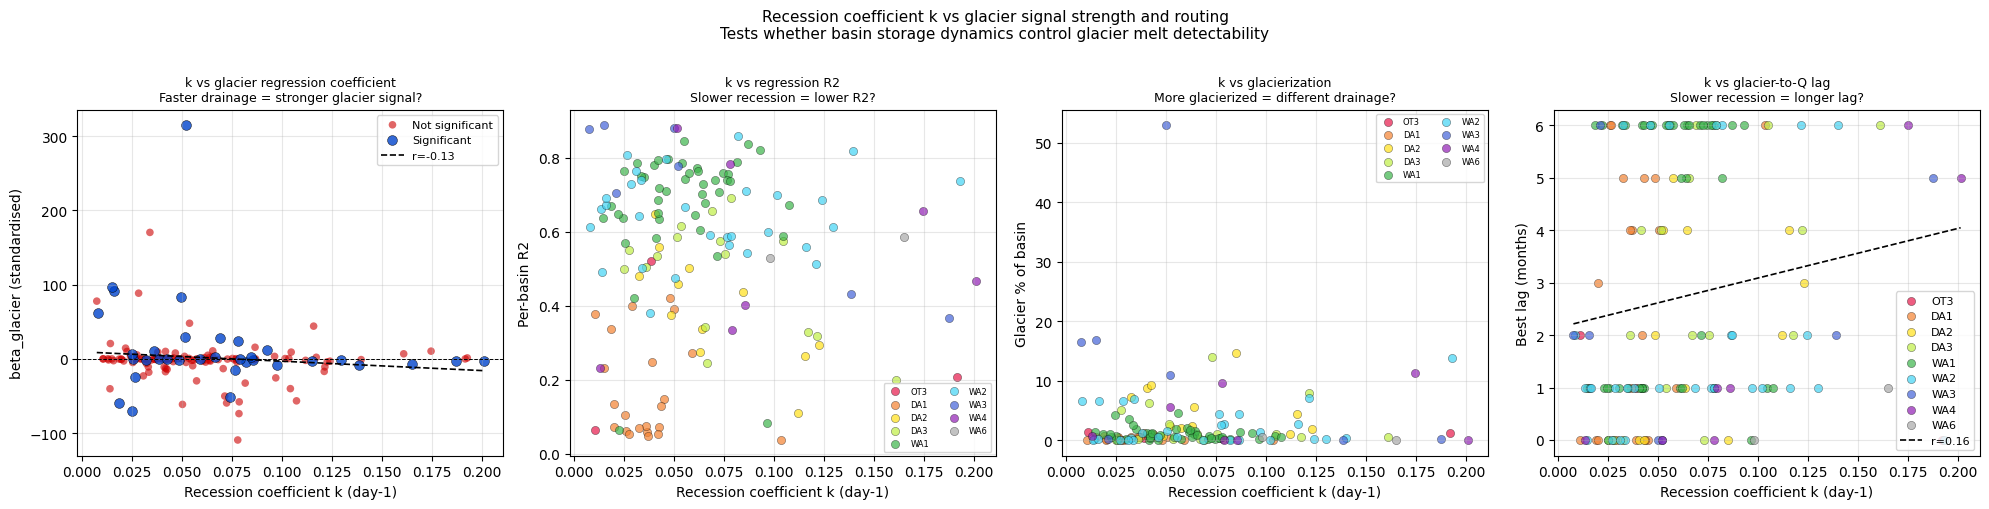

Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/megadrought_analysis/all_glacierized/recession_coefficients_all_basins.csv


In [23]:
pred   = 'coef_glacier_runoff_m3'
lo_col = 'ci_lo_glacier_runoff_m3'
hi_col = 'ci_hi_glacier_runoff_m3'

reg_path = f'{OUT_DIR}/regression/per_basin_regression_partA_CR2MET.csv'
if os.path.exists(reg_path):
    df_reg = pd.read_csv(reg_path, dtype={'gauge_id': str})
    df_reg['sig'] = ((df_reg[lo_col] > 0) | (df_reg[hi_col] < 0))
    print(f'Regression results loaded: {len(df_reg)} basins')
else:
    print(f'Regression CSV not found at {reg_path}')
    print('Point this at 04_regression_analysis.ipynb REG_DIR output instead')
    df_reg = pd.DataFrame(columns=['gauge_id', pred, lo_col, hi_col, 'sig', 'r2'])

lag_path = f'{OUT_DIR}/lag_analysis/lag_results_CR2MET.csv'
if os.path.exists(lag_path):
    df_lag  = pd.read_csv(lag_path, dtype={'gauge_id': str})
    has_lag = True
    print(f'Lag results loaded: {len(df_lag)} gauges')
else:
    has_lag = False
    print('Lag results not found at legacy path -- skipping lag panel')

df_k_reg = df_rec_full.merge(
    df_reg[['gauge_id', pred, lo_col, hi_col, 'sig', 'r2']], on='gauge_id', how='left')

if has_lag:
    df_k_reg = df_k_reg.merge(
        df_lag[['gauge_id', 'best_lag_months', 'best_r']], on='gauge_id', how='left')

print('Key correlations with recession coefficient k:')
print()

test_vars = [
    (pred,               'beta_glacier (regression coef)'),
    ('r2',               'Per-basin R2'),
    ('glac_pct',         'Glacier % of basin'),
    ('glacier_area_km2', 'Glacier area (km2)'),
]
if has_lag:
    test_vars.append(('best_lag_months', 'Best lag (months)'))

for col, label in test_vars:
    sub = df_k_reg[['k_median', col]].dropna()
    if len(sub) < 5:
        continue
    r, p = stats.pearsonr(sub['k_median'], sub[col])
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f'  k vs {label:35s}: r={r:+.3f}  p={p:.3e}  {sig}')

n_panels = 4 if has_lag else 3
fig, axes = plt.subplots(1, n_panels, figsize=(5*n_panels, 5))

ax = axes[0]
sig_mask = df_k_reg['sig'] == True
ax.scatter(df_k_reg.loc[~sig_mask, 'k_median'], df_k_reg.loc[~sig_mask, pred],
           c='#cc0000', s=30, alpha=0.6, edgecolors='none', label='Not significant')
ax.scatter(df_k_reg.loc[sig_mask, 'k_median'], df_k_reg.loc[sig_mask, pred],
           c='#0044cc', s=50, alpha=0.8, edgecolors='k', lw=0.4, label='Significant')
ax.axhline(0, color='k', lw=0.7, ls='--')
ax.set_xlabel('Recession coefficient k (day-1)', fontsize=10)
ax.set_ylabel('beta_glacier (standardised)', fontsize=10)
ax.set_title('k vs glacier regression coefficient\nFaster drainage = stronger glacier signal?', fontsize=9)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

sub = df_k_reg[[pred, 'k_median']].dropna()
if len(sub) > 5:
    slope, intercept, r, p, _ = stats.linregress(sub['k_median'], sub[pred])
    xfit = np.linspace(sub['k_median'].min(), sub['k_median'].max(), 100)
    ax.plot(xfit, slope*xfit + intercept, 'k--', lw=1.2, label=f'r={r:.2f}')
    ax.legend(fontsize=8)

ax = axes[1]
for cl in CLUSTERS:
    grp = df_k_reg[df_k_reg['cluster'] == cl].dropna(subset=['k_median','r2'])
    if len(grp) == 0:
        continue
    ax.scatter(grp['k_median'], grp['r2'], c=cluster_colors_map.get(cl, '#888'),
               s=35, alpha=0.7, edgecolors='k', lw=0.3, label=cl)
ax.set_xlabel('Recession coefficient k (day-1)', fontsize=10)
ax.set_ylabel('Per-basin R2', fontsize=10)
ax.set_title('k vs regression R2\nSlower recession = lower R2?', fontsize=9)
ax.legend(fontsize=6, ncol=2); ax.grid(True, alpha=0.3)

ax = axes[2]
for cl in CLUSTERS:
    grp = df_k_reg[df_k_reg['cluster'] == cl].dropna(subset=['k_median','glac_pct'])
    if len(grp) == 0:
        continue
    ax.scatter(grp['k_median'], grp['glac_pct'], c=cluster_colors_map.get(cl, '#888'),
               s=35, alpha=0.7, edgecolors='k', lw=0.3, label=cl)
ax.set_xlabel('Recession coefficient k (day-1)', fontsize=10)
ax.set_ylabel('Glacier % of basin', fontsize=10)
ax.set_title('k vs glacierization\nMore glacierized = different drainage?', fontsize=9)
ax.legend(fontsize=6, ncol=2); ax.grid(True, alpha=0.3)

if has_lag:
    ax = axes[3]
    for cl in CLUSTERS:
        grp = df_k_reg[df_k_reg['cluster'] == cl].dropna(subset=['k_median','best_lag_months'])
        if len(grp) == 0:
            continue
        ax.scatter(grp['k_median'], grp['best_lag_months'], c=cluster_colors_map.get(cl, '#888'),
                   s=35, alpha=0.7, edgecolors='k', lw=0.3, label=cl)
    ax.set_xlabel('Recession coefficient k (day-1)', fontsize=10)
    ax.set_ylabel('Best lag (months)', fontsize=10)
    ax.set_title('k vs glacier-to-Q lag\nSlower recession = longer lag?', fontsize=9)
    ax.legend(fontsize=6, ncol=2); ax.grid(True, alpha=0.3)

    sub = df_k_reg[['k_median','best_lag_months']].dropna()
    if len(sub) > 5:
        slope, intercept, r, p, _ = stats.linregress(sub['k_median'], sub['best_lag_months'])
        xfit = np.linspace(sub['k_median'].min(), sub['k_median'].max(), 100)
        axes[3].plot(xfit, slope*xfit + intercept, 'k--', lw=1.2, label=f'r={r:.2f}')
        axes[3].legend(fontsize=8)

fig.suptitle(
    'Recession coefficient k vs glacier signal strength and routing\n'
    'Tests whether basin storage dynamics control glacier melt detectability',
    fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/recession_k_vs_glacier_signal.png', dpi=150, bbox_inches='tight')
plt.show()

df_k_reg.to_csv(f'{DROUGHT_DIR}/recession_coefficients_all_basins.csv', index=False)
print(f'Saved: {DROUGHT_DIR}/recession_coefficients_all_basins.csv')


## Becca's routing idea: route glacier melt through basin storage before computing fraction

Applies each basin's recession coefficient k to shift glacier melt
forward in time (exponential decay kernel) before dividing by observed
Q. **Framing note (Becca):** this does NOT imply all glacier melt
reaches streamflow. Storage, evaporation, and deep groundwater loss are
not accounted for -- the routed fraction is a timing index, not a water
balance closure.

In [24]:
rec_path = f'{DROUGHT_DIR}/recession_coefficients_all_basins.csv'
if os.path.exists(rec_path):
    df_rec = pd.read_csv(rec_path, dtype={'gauge_id': str})
    k_by_gauge = df_rec.groupby('gauge_id')['k_median'].median().to_dict()
    print(f'Recession coefficients loaded: {len(k_by_gauge)} basins')
else:
    k_by_gauge = {}
    print(f'WARNING: recession coefficients CSV not found at {rec_path}')

K_CLUSTER_MEDIANS = {'OT3': 0.025, 'DA1': 0.037, 'DA2': 0.055, 'DA3': 0.068,
                     'WA1': 0.055, 'WA2': 0.062, 'WA3': 0.050, 'WA4': 0.079, 'WA6': 0.132}

print('Computing routed glacier fractions for all basins...')

routed_records = []

for gauge_id, info in GAUGE_INFO_FRAC.items():
    gid_str = str(gauge_id)
    k = k_by_gauge.get(gid_str, None)
    if k is None:
        cl = info['clusters'][0]
        k = K_CLUSTER_MEDIANS.get(cl, 0.05)
        k_source = 'cluster_median'
    else:
        k_source = 'basin_specific'

    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        res = RESULTS[ds_name].get(gauge_id)
        if res is None:
            continue
        m  = res['monthly']
        cy = res.get('complete_years', YEARS)
        mc = (m[m['year'].isin(cy)].sort_values(['year','month']).reset_index(drop=True))

        if len(mc) < 12:
            continue

        glac = mc['glacier_runoff_m3'].values.astype(float)
        q    = mc['q_m3_mon'].values.astype(float)
        n    = len(glac)

        max_lag = 12
        lags = np.arange(0, max_lag + 1)
        weights = np.exp(-k * lags * 30)
        weights = weights / weights.sum()

        routed = np.zeros(n)
        for i in range(n):
            for lag, w in enumerate(weights):
                if i + lag < n:
                    routed[i + lag] += glac[i] * w

        mc['routed_glac_m3'] = routed

        ann = mc.groupby('year').agg(raw_glac=('glacier_runoff_m3', 'sum'),
                                     routed_glac=('routed_glac_m3', 'sum'),
                                     q_tot=('q_m3_mon', 'sum')).reset_index()
        ann = ann[ann['q_tot'] > 0]
        if len(ann) == 0:
            continue

        ann_raw_frac    = (ann['raw_glac']    / ann['q_tot']).mean() * 100
        ann_routed_frac = (ann['routed_glac'] / ann['q_tot']).mean() * 100

        mc_mar = mc[mc['month'] == 3]
        mc_mar = mc_mar[mc_mar['q_m3_mon'] > 0]
        mar_raw_frac    = (mc_mar['glacier_runoff_m3'] / mc_mar['q_m3_mon']).mean()*100 if len(mc_mar) else np.nan
        mar_routed_frac = (mc_mar['routed_glac_m3']    / mc_mar['q_m3_mon']).mean()*100 if len(mc_mar) else np.nan

        routed_records.append({
            'gauge_id': gauge_id, 'gauge_name': info['gauge_name'][:35], 'lat': info['cen_lat'],
            'cluster': info['clusters'][0], 'glacier_area_km2': info['glacier_area_km2'],
            'basin_area_km2': info.get('basin_area_km2', np.nan), 'dataset': ds_name,
            'k': k, 'k_source': k_source,
            'ann_raw_frac': ann_raw_frac, 'ann_routed_frac': ann_routed_frac,
            'ann_diff': ann_routed_frac - ann_raw_frac,
            'mar_raw_frac': mar_raw_frac, 'mar_routed_frac': mar_routed_frac,
            'mar_diff': mar_routed_frac - mar_raw_frac if mar_routed_frac is not None else np.nan,
        })

df_routed = pd.DataFrame(routed_records)
print(f'Routed fraction records: {len(df_routed):,}')

print()
print('Impact of routing on glacier fraction (CR2MET, cluster means):')
print(f'{"Cluster":6s} {"k":6s} {"Ann raw%":9s} {"Ann rout%":10s} {"Diff":6s} {"Mar raw%":9s} {"Mar rout%":10s} {"Diff"}')
print('-' * 75)

cr2 = df_routed[df_routed['dataset'] == 'CR2MET']
for cl in CLUSTERS:
    sub = cr2[cr2['cluster'] == cl]
    if len(sub) == 0:
        continue
    k_med = sub['k'].median()
    print(f'{cl:6s} {k_med:.3f} {sub["ann_raw_frac"].mean():9.2f} {sub["ann_routed_frac"].mean():10.2f} '
          f'{sub["ann_diff"].mean():+6.2f} {sub["mar_raw_frac"].mean():9.2f} '
          f'{sub["mar_routed_frac"].mean():10.2f} {sub["mar_diff"].mean():+6.2f}')

df_routed.to_csv(f'{DROUGHT_DIR}/glacier_fractions_routed.csv', index=False)
print(f'Saved: {DROUGHT_DIR}/glacier_fractions_routed.csv')
print()
print('FRAMING NOTE (Becca): routed fractions improve the TIMING of the comparison')
print('only. They do NOT imply all glacier melt reaches the stream -- storage,')
print('deep groundwater loss, and evaporation are not accounted for.')


Recession coefficients loaded: 143 basins
Computing routed glacier fractions for all basins...
Routed fraction records: 429

Impact of routing on glacier fraction (CR2MET, cluster means):
Cluster k      Ann raw%  Ann rout%  Diff   Mar raw%  Mar rout%  Diff
---------------------------------------------------------------------------
OT3    0.039     46.28      46.29  +0.00    135.21     135.31  +0.10
DA1    0.036     26.93      26.78  -0.15     52.99      80.28 +27.28
DA2    0.060     42.61      42.58  -0.03    527.60     541.48 +13.87
DA3    0.068     25.35      25.31  -0.04    371.98     379.14  +7.17
WA1    0.055      3.68       3.68  -0.00     17.19      17.63  +0.44
WA2    0.062      5.34       5.31  -0.03      9.40       9.71  +0.30
WA3    0.050     21.63      21.34  -0.29     23.25      22.38  -0.88
WA4    0.079      8.85       8.82  -0.03     11.60      12.74  +1.15
WA6    0.132      0.46       0.46  -0.00      1.16       1.19  +0.03
Saved: /Users/milliespencer/Desktop/CR2_OGGM_P

## Spatial map: annual fraction, drought amplification, and recession k

Three-panel Chile-wide map (annual glacier fraction, drought
amplification factor, recession coefficient k), plus a table of the
20 most drought-amplified basins nationally.

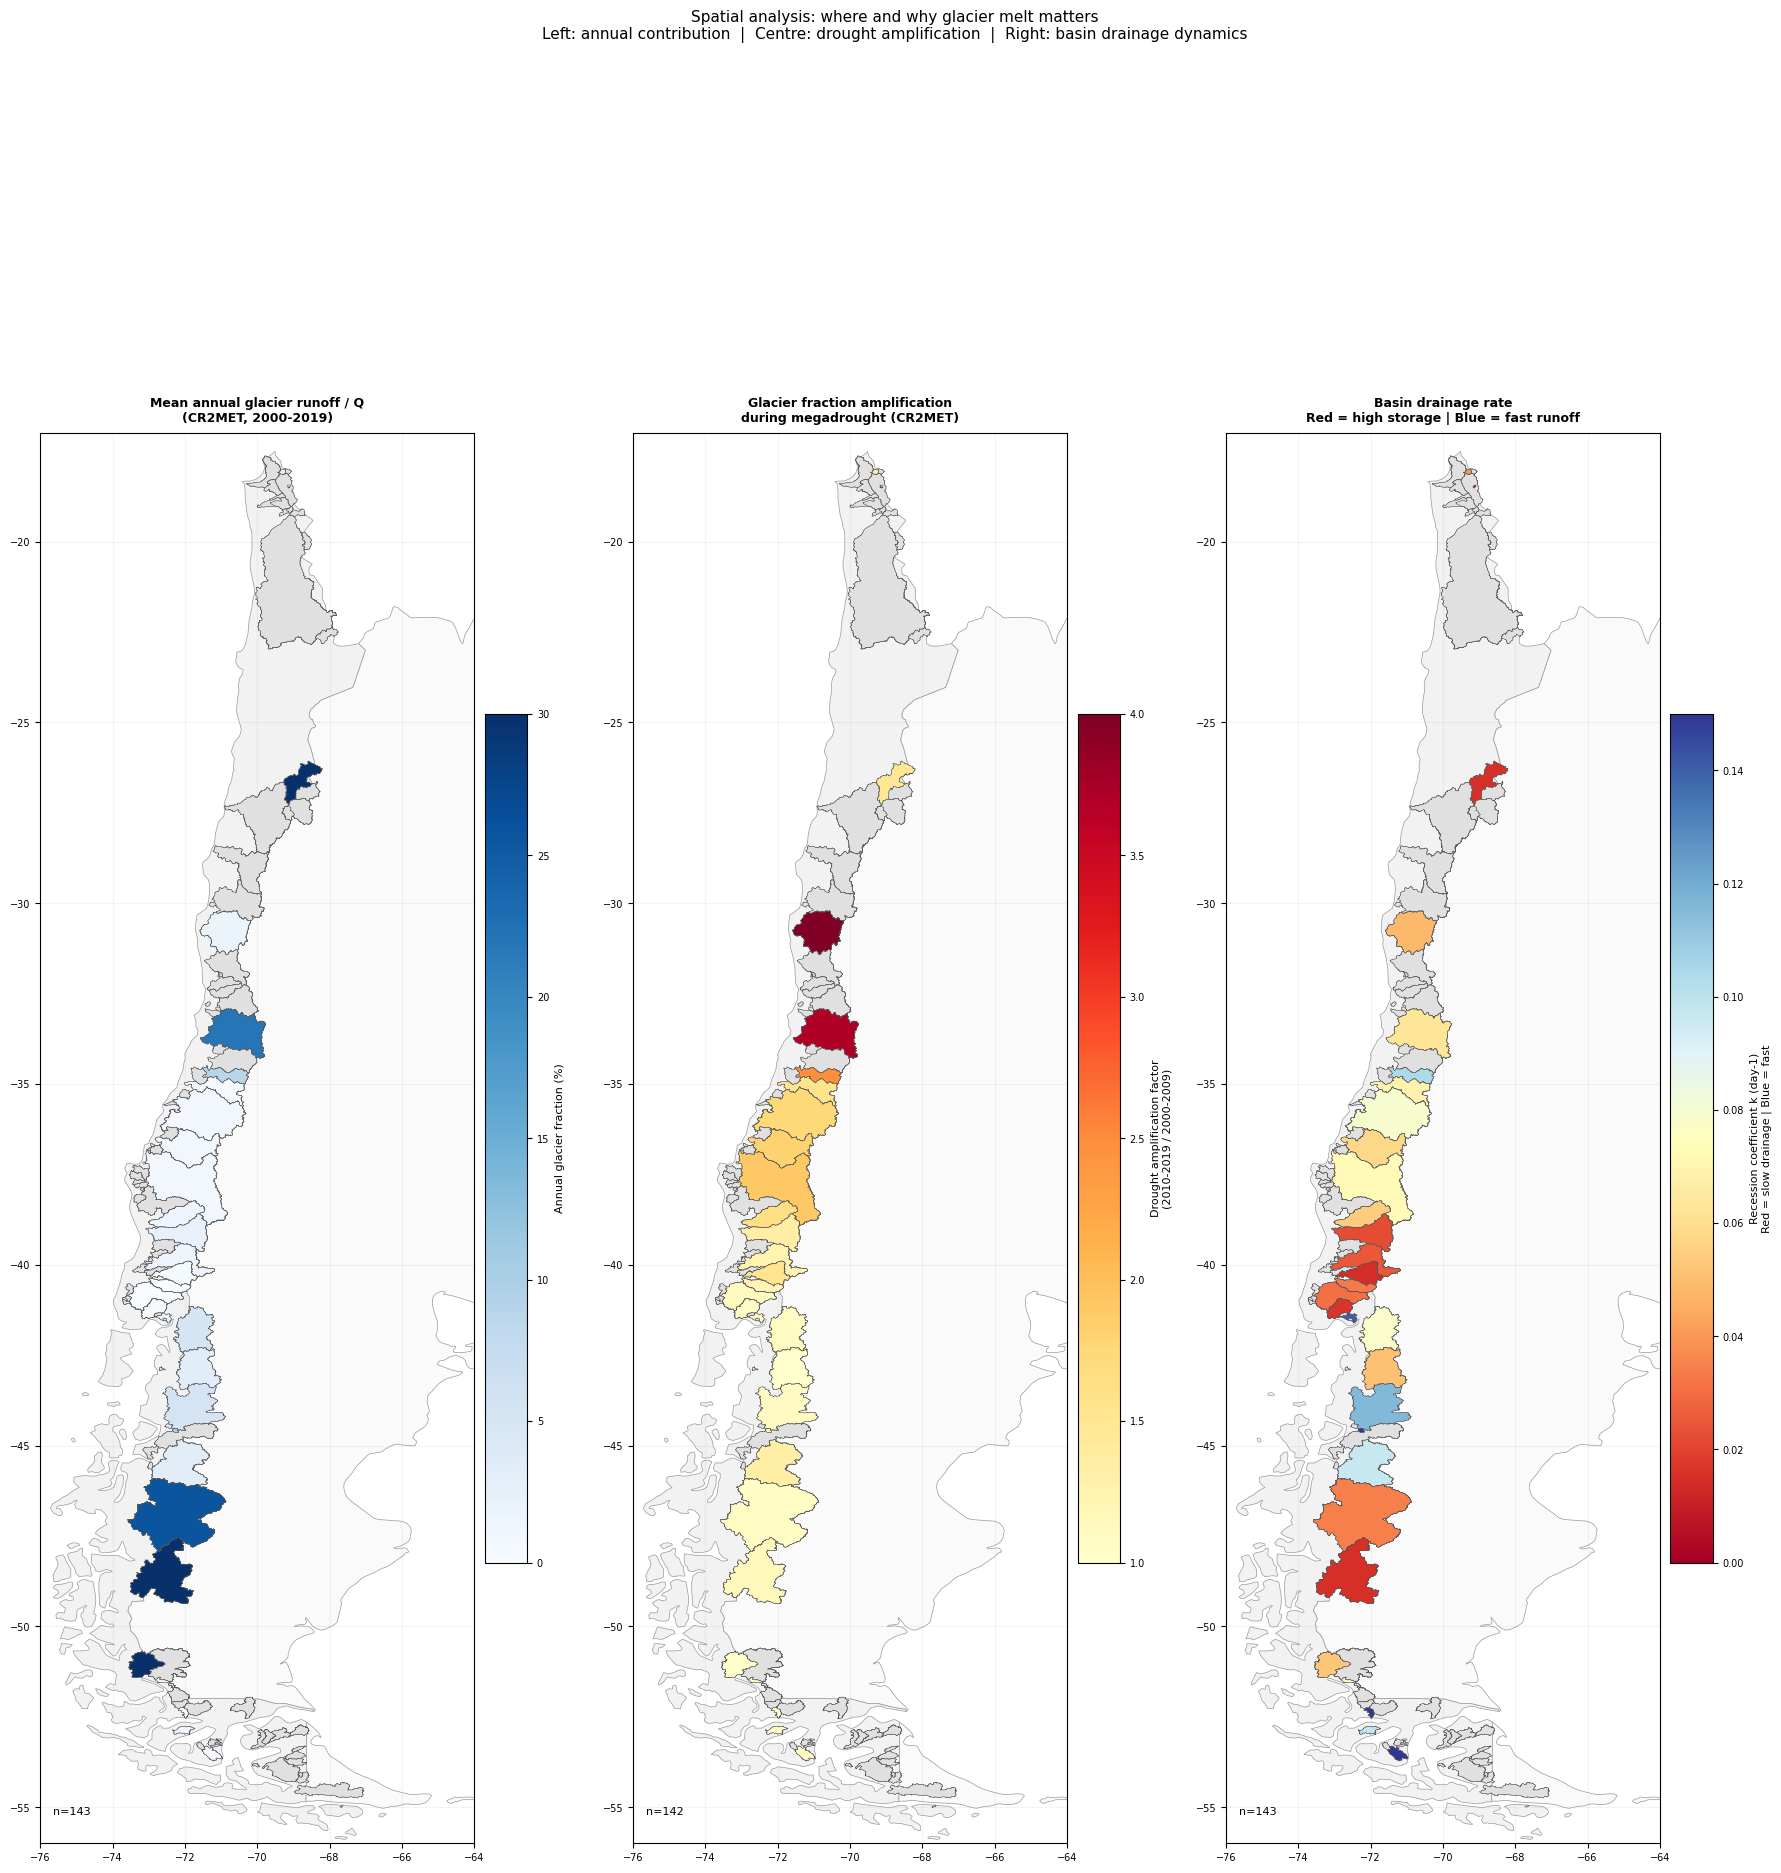

Top 20 most drought-amplified basins (CR2MET, 2010-2019 vs baseline):
  7357002    Rio Loncomilla En Bodega            amp=7.23x  ann_frac=1.6%  cluster=WA1  lat=-36.2S
  5410005    Rio Aconcagua En San Felipe         amp=6.68x  ann_frac=23.2%  cluster=DA2  lat=-33.0S
  7321002    Rio Maule En Armerillo              amp=6.22x  ann_frac=23.5%  cluster=DA3  lat=-36.0S
  5423003    Rio Aconcagua En Romeral            amp=5.80x  ann_frac=20.1%  cluster=DA2  lat=-33.0S
  4558001    Rio Limari En Panamericana          amp=5.42x  ann_frac=1.8%  cluster=DA1  lat=-30.5S
  5406001    Rio Colorado En Colorado            amp=4.78x  ann_frac=204.1%  cluster=DA2  lat=-33.0S
  7317005    Rio Melado En El Salto              amp=4.49x  ann_frac=5.6%  cluster=DA3  lat=-36.1S
  3421001    Rio Manflas En Vertedero            amp=4.16x  ann_frac=61.8%  cluster=DA1  lat=-28.6S
  6008005    Rio Cachapoal En Pte Termas De Cauq amp=4.09x  ann_frac=105.8%  cluster=DA3  lat=-34.4S
  5748001    Rio Maipo En Cabim

In [25]:
from matplotlib.colors import Normalize, to_hex
from matplotlib.cm import ScalarMappable

if 'bounds' not in dir():
    bounds = gpd.read_file(BOUNDS_PATH)
    bounds['gauge_id'] = bounds['gauge_id'].astype(str)

if 'chile' not in dir():
    try:
        world = gpd.read_file('https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip')
        chile = world[world['NAME'] == 'Chile']
        arg   = world[world['NAME'] == 'Argentina']
        has_borders = True
    except Exception:
        has_borders = False

frac_by_gauge = {}
for gauge_id, res in RESULTS['CR2MET'].items():
    if res is None:
        continue
    m  = res['monthly']
    cy = res.get('complete_years', YEARS)
    ann = (m[m['year'].isin(cy)].groupby('year')
           .agg(glac=('glacier_runoff_m3','sum'), q=('q_m3_mon','sum')))
    ann = ann[ann['q'] > 0]
    if len(ann):
        frac_by_gauge[gauge_id] = (ann['glac']/ann['q']).mean() * 100

amp_by_gauge = {}
for gauge_id, res in RESULTS['CR2MET'].items():
    if res is None:
        continue
    info = GAUGE_INFO_FRAC.get(gauge_id)
    if info is None:
        continue
    m  = res['monthly']
    cy = res.get('complete_years', YEARS)

    def period_frac(years):
        valid = [y for y in years if y in cy]
        if len(valid) < 2:
            return np.nan
        sub = m[m['year'].isin(valid)]
        ann = sub.groupby('year').agg(glac=('glacier_runoff_m3','sum'), q=('q_m3_mon','sum'))
        ann = ann[ann['q'] > 0]
        return (ann['glac']/ann['q']).mean() if len(ann) else np.nan

    f_base    = period_frac(BASELINE)
    f_drought = period_frac(list(range(2010, 2020)))
    if not any(np.isnan([f_base, f_drought])) and f_base > 0:
        amp_by_gauge[gauge_id] = f_drought / f_base

bounds_plot = bounds.copy()
bounds_plot['frac_ann']   = bounds_plot['gauge_id'].map(frac_by_gauge)
bounds_plot['amp_factor'] = bounds_plot['gauge_id'].map(amp_by_gauge)
bounds_plot['k_median']   = bounds_plot['gauge_id'].map(
    df_recession.set_index('gauge_id')['k_median'].to_dict())

fig, axes = plt.subplots(1, 3, figsize=(18, 22))

map_configs = [
    ('frac_ann', plt.cm.Blues, Normalize(0, 30),
     'Annual glacier fraction (%)', 'Mean annual glacier runoff / Q\n(CR2MET, 2000-2019)'),
    ('amp_factor', plt.cm.YlOrRd, Normalize(1, 4),
     'Drought amplification factor\n(2010-2019 / 2000-2009)', 'Glacier fraction amplification\nduring megadrought (CR2MET)'),
    ('k_median', plt.cm.RdYlBu, Normalize(0.00, 0.15),
     'Recession coefficient k (day-1)\nRed = slow drainage | Blue = fast',
     'Basin drainage rate\nRed = high storage | Blue = fast runoff'),
]

for ax, (col, cmap, norm, cbar_label, title) in zip(axes, map_configs):
    if has_borders:
        chile.plot(ax=ax, facecolor='#f2f2f2', edgecolor='#999999', linewidth=0.5, zorder=0)
        arg.plot(ax=ax, facecolor='#fafafa', edgecolor='#999999', linewidth=0.5, zorder=0)

    bounds.plot(ax=ax, facecolor='#e0e0e0', edgecolor='#cccccc', linewidth=0.2, zorder=1)

    face_colors = [to_hex(cmap(norm(v))) if (v is not None and not np.isnan(v)) else '#e0e0e0'
                   for v in bounds_plot[col].values]
    bounds_plot.plot(ax=ax, color=face_colors, edgecolor='#555555', linewidth=0.3, zorder=2)

    ax.set_xlim(-76, -64); ax.set_ylim(-56, -17); ax.set_aspect('equal')
    ax.tick_params(labelsize=7); ax.grid(True, alpha=0.15)
    ax.set_title(title, fontsize=9, fontweight='bold', pad=8)

    n_valid = bounds_plot[col].notna().sum()
    ax.text(0.03, 0.02, f'n={n_valid}', transform=ax.transAxes, fontsize=8)

    sm = ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, shrink=0.4, pad=0.02)
    cb.set_label(cbar_label, fontsize=8); cb.ax.tick_params(labelsize=7)

fig.suptitle(
    'Spatial analysis: where and why glacier melt matters\n'
    'Left: annual contribution  |  Centre: drought amplification  |  Right: basin drainage dynamics',
    fontsize=11, y=1.002)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/spatial_analysis_three_maps.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 20 most drought-amplified basins (CR2MET, 2010-2019 vs baseline):')
top_amp = (pd.DataFrame({'gauge_id': list(amp_by_gauge.keys()), 'amp_factor': list(amp_by_gauge.values())})
           .sort_values('amp_factor', ascending=False).head(20))

for _, row in top_amp.iterrows():
    gid  = row['gauge_id']
    info = GAUGE_INFO_FRAC.get(gid, {})
    frac = frac_by_gauge.get(gid, np.nan)
    print(f'  {gid:10s} {info.get("gauge_name","")[:35]:35s} '
          f'amp={row["amp_factor"]:.2f}x  ann_frac={frac:.1f}%  '
          f'cluster={info.get("clusters",["?"])[0]}  lat={info.get("cen_lat",np.nan):.1f}S')


## Basin aridity analysis (Becca)

Aridity index (PET/P) characterizes how water-limited a basin is. In
more arid basins, glaciers should be proportionally more important as a
water source since there are fewer alternatives. Uses
`aridity_cr2met_1979_2010` from CAMELS-CL catchment attributes.

Aridity analysis dataset: 143 basins
Aridity index by cluster (CR2MET 1979-2010):
         median   min    max
cluster                     
DA1        5.89  3.71  10.51
DA2        1.25  0.75   2.10
DA3        0.54  0.43   0.89
OT3        2.02  1.95   2.10
WA1        0.47  0.28   1.06
WA2        0.44  0.26   1.49
WA3        0.88  0.29   2.58
WA4        0.81  0.29   3.89
WA6        0.72  0.63   0.81


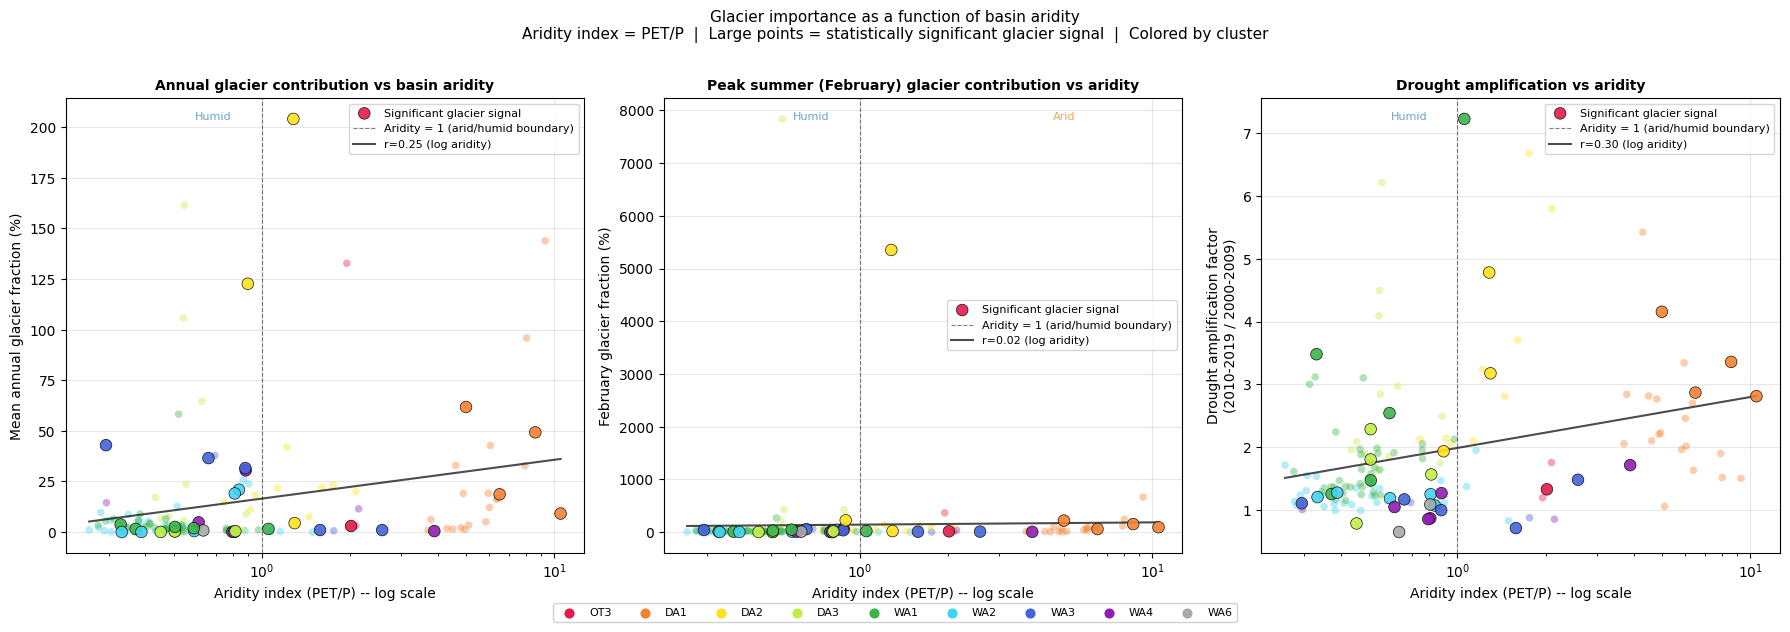

In [26]:
attrs = pd.read_csv(f'{CAMELS_FULL}/catchment_attributes.csv', dtype={'gauge_id': str})

attr_cols = ['gauge_id', 'gauge_lat', 'gauge_lon',
             'aridity_cr2met_1979_2010', 'aridity_cr2met_1990_2010',
             'mean_elev', 'med_elev', 'max_elev', 'outlet_camels_elev', 'mean_slope_perc',
             'baseflow_index_1979_2010', 'frac_snow_cr2met_1979_2010',
             'p_mean_cr2met_1979_2010', 'pet_mean_1979_2010', 'q_mean_1979_2010',
             'runoff_ratio_cr2met_1979_2010']
attrs_sub = attrs[[c for c in attr_cols if c in attrs.columns]].copy()

frac_records = []
for gauge_id, res in RESULTS['CR2MET'].items():
    if res is None:
        continue
    info = GAUGE_INFO_FRAC.get(gauge_id)
    if info is None:
        continue
    m  = res['monthly']
    cy = res.get('complete_years', YEARS)

    ann = (m[m['year'].isin(cy)].groupby('year')
           .agg(glac=('glacier_runoff_m3','sum'), q=('q_m3_mon','sum')))
    ann = ann[ann['q'] > 0]
    if len(ann) == 0:
        continue

    f_base    = (ann.loc[ann.index.isin(BASELINE), 'glac'] / ann.loc[ann.index.isin(BASELINE), 'q']).mean()
    f_drought = (ann.loc[ann.index.isin(range(2010,2020)), 'glac'] / ann.loc[ann.index.isin(range(2010,2020)), 'q']).mean()
    amp = f_drought / f_base if (f_base > 0 and not np.isnan(f_base)) else np.nan

    feb = m[(m['month'] == 2) & m['year'].isin(cy)]
    feb = feb[feb['q_m3_mon'] > 0]
    feb_frac = (feb['glacier_runoff_m3'] / feb['q_m3_mon']).mean() * 100 if len(feb) else np.nan

    frac_records.append({
        'gauge_id': gauge_id, 'gauge_name': info['gauge_name'][:35], 'lat': info['cen_lat'],
        'cluster': info['clusters'][0], 'glacier_area_km2': info['glacier_area_km2'],
        'basin_area_km2': info.get('basin_area_km2', np.nan),
        'glac_pct': info['glacier_area_km2'] / info.get('basin_area_km2', np.nan) * 100
                    if info.get('basin_area_km2') else np.nan,
        'mean_ann_frac': (ann['glac'] / ann['q']).mean() * 100,
        'feb_frac': feb_frac, 'amp_factor': amp,
    })

df_aridity = pd.DataFrame(frac_records).merge(attrs_sub, on='gauge_id', how='left')

pred, lo_col, hi_col = 'coef_glacier_runoff_m3', 'ci_lo_glacier_runoff_m3', 'ci_hi_glacier_runoff_m3'
reg_path = f'{OUT_DIR}/regression/per_basin_regression_partA_CR2MET.csv'
if os.path.exists(reg_path):
    df_cr2_sig = pd.read_csv(reg_path, dtype={'gauge_id': str})
    df_cr2_sig['sig'] = ((df_cr2_sig[lo_col] > 0) | (df_cr2_sig[hi_col] < 0))
    df_aridity = df_aridity.merge(
        df_cr2_sig[['gauge_id','sig', pred, 'r2']].rename(columns={pred: 'beta_glacier'}),
        on='gauge_id', how='left')
else:
    print(f'Regression CSV not found at {reg_path} -- sig/beta columns will be NaN')
    df_aridity['sig'] = np.nan
    df_aridity['beta_glacier'] = np.nan
    df_aridity['r2'] = np.nan

print(f'Aridity analysis dataset: {len(df_aridity)} basins')
print('Aridity index by cluster (CR2MET 1979-2010):')
print(df_aridity.groupby('cluster')['aridity_cr2met_1979_2010'].agg(['median','min','max']).round(2).to_string())

cluster_colors_map = {
    'OT3':'#e6194b', 'DA1':'#f58231', 'DA2':'#ffe119', 'DA3':'#bfef45',
    'WA1':'#3cb44b', 'WA2':'#42d4f4', 'WA3':'#4363d8', 'WA4':'#911eb4', 'WA6':'#a9a9a9'
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

plot_configs = [
    ('mean_ann_frac', 'Mean annual glacier fraction (%)', 'Annual glacier contribution vs basin aridity'),
    ('feb_frac', 'February glacier fraction (%)', 'Peak summer (February) glacier contribution vs aridity'),
    ('amp_factor', 'Drought amplification factor\n(2010-2019 / 2000-2009)', 'Drought amplification vs aridity'),
]

for ax, (ycol, ylabel, title) in zip(axes, plot_configs):
    sub = df_aridity[['aridity_cr2met_1979_2010', ycol, 'cluster', 'sig']].dropna()

    ns = sub[sub['sig'] == False]
    ax.scatter(ns['aridity_cr2met_1979_2010'], ns[ycol],
               c=[cluster_colors_map.get(c,'#888') for c in ns['cluster']],
               s=30, alpha=0.4, edgecolors='none', zorder=2)

    sg = sub[sub['sig'] == True]
    ax.scatter(sg['aridity_cr2met_1979_2010'], sg[ycol],
               c=[cluster_colors_map.get(c,'#888') for c in sg['cluster']],
               s=70, alpha=0.9, edgecolors='k', lw=0.5, zorder=3, label='Significant glacier signal')

    ax.set_xscale('log')
    ax.axvline(1.0, color='k', lw=0.8, ls='--', alpha=0.5, label='Aridity = 1 (arid/humid boundary)')

    x = np.log10(sub['aridity_cr2met_1979_2010'].clip(lower=0.1))
    y = sub[ycol]
    if len(x) > 5:
        slope, intercept, r, p, _ = stats.linregress(x, y)
        xfit_log = np.linspace(x.min(), x.max(), 100)
        xfit = 10**xfit_log
        ax.plot(xfit, slope*xfit_log + intercept, 'k-', lw=1.5, alpha=0.7, label=f'r={r:.2f} (log aridity)')

    ax.set_xlabel('Aridity index (PET/P) -- log scale', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

    ax.text(0.25, 0.97, 'Humid', transform=ax.transAxes, fontsize=8, va='top', color='#2980b9', alpha=0.7)
    ax.text(0.75, 0.97, 'Arid', transform=ax.transAxes, fontsize=8, va='top', color='#e67e22', alpha=0.7)

handles = [plt.scatter([],[], c=cluster_colors_map.get(cl,'#888'), s=40, label=cl)
           for cl in CLUSTERS if cl in cluster_colors_map]
fig.legend(handles=handles, loc='lower center', ncol=len(handles), fontsize=8, bbox_to_anchor=(0.5, -0.02), framealpha=0.9)

fig.suptitle(
    'Glacier importance as a function of basin aridity\n'
    'Aridity index = PET/P  |  Large points = statistically significant glacier signal  |  Colored by cluster',
    fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/aridity_vs_glacier_importance.png', dpi=150, bbox_inches='tight')
plt.show()


Correlation of aridity with glacier importance metrics:

Aridity vs annual glacier fraction:
  Raw aridity:     r=+0.252  p=2.401e-03  **
  Log10 aridity:   r=+0.255  p=2.147e-03  **

Aridity vs February glacier fraction:
  Raw aridity:     r=+0.003  p=9.755e-01  ns
  Log10 aridity:   r=+0.023  p=7.848e-01  ns

Aridity vs drought amplification factor:
  Raw aridity:     r=+0.224  p=7.053e-03  **
  Log10 aridity:   r=+0.297  p=3.167e-04  ***

Aridity vs beta_glacier (regression coef):
  Raw aridity:     r=-0.004  p=9.595e-01  ns
  Log10 aridity:   r=+0.041  p=6.259e-01  ns

Median glacier fraction by aridity class:
                     mean_ann_frac       feb_frac       amp_factor      
                            median count   median count     median count
aridity_class                                                           
<0.5\n(very humid)            2.61    49    13.07    49       1.35    49
0.5-1.0\n(humid)              2.21    52    20.63    52       1.57    52
1.0-2.0\n(sem

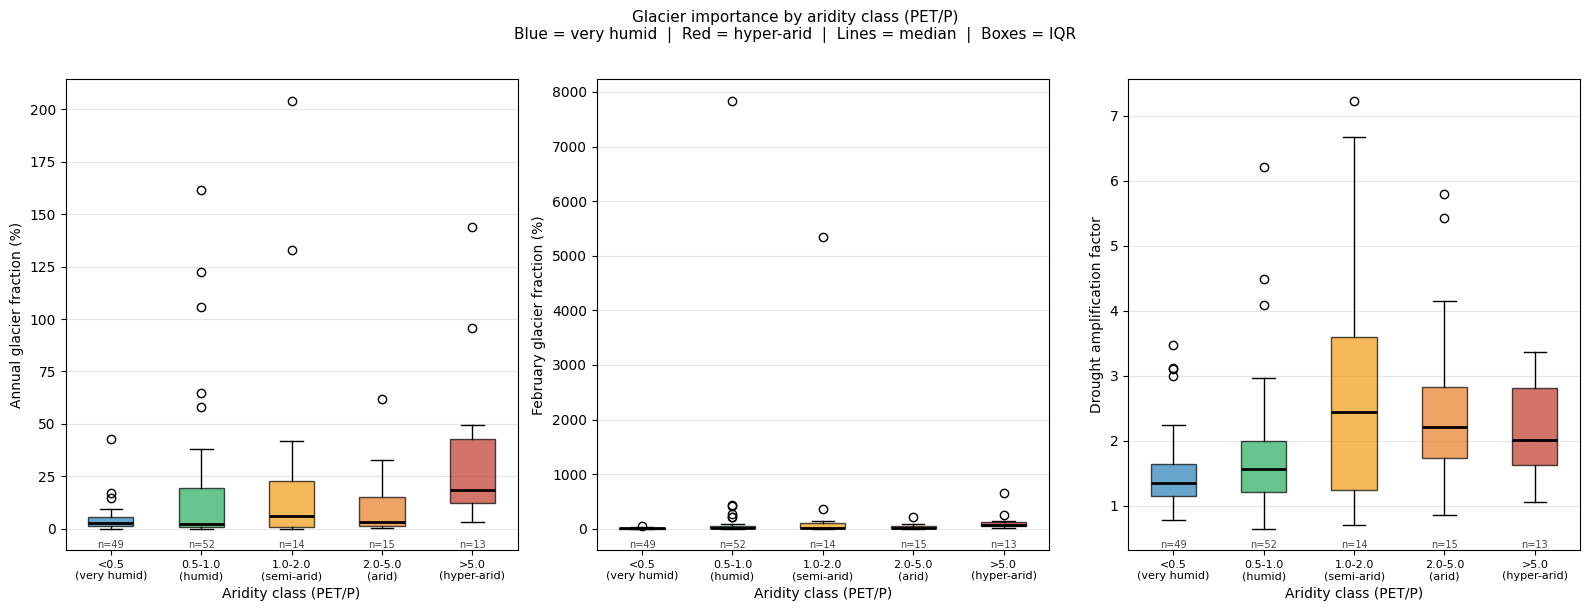

In [27]:
print('Correlation of aridity with glacier importance metrics:')
print()

test_pairs = [
    ('aridity_cr2met_1979_2010', 'mean_ann_frac', 'Aridity vs annual glacier fraction'),
    ('aridity_cr2met_1979_2010', 'feb_frac', 'Aridity vs February glacier fraction'),
    ('aridity_cr2met_1979_2010', 'amp_factor', 'Aridity vs drought amplification factor'),
    ('aridity_cr2met_1979_2010', 'beta_glacier', 'Aridity vs beta_glacier (regression coef)'),
]

for xcol, ycol, label in test_pairs:
    sub = df_aridity[[xcol, ycol]].dropna()
    if len(sub) < 5:
        continue
    r_raw, p_raw = stats.pearsonr(sub[xcol], sub[ycol])
    r_log, p_log = stats.pearsonr(np.log10(sub[xcol].clip(lower=0.1)), sub[ycol])
    sig_raw = '***' if p_raw < 0.001 else '**' if p_raw < 0.01 else '*' if p_raw < 0.05 else 'ns'
    sig_log = '***' if p_log < 0.001 else '**' if p_log < 0.01 else '*' if p_log < 0.05 else 'ns'
    print(f'{label}:')
    print(f'  Raw aridity:     r={r_raw:+.3f}  p={p_raw:.3e}  {sig_raw}')
    print(f'  Log10 aridity:   r={r_log:+.3f}  p={p_log:.3e}  {sig_log}')
    print()

bins   = [0, 0.5, 1.0, 2.0, 5.0, 30.0]
labels = ['<0.5\n(very humid)', '0.5-1.0\n(humid)', '1.0-2.0\n(semi-arid)', '2.0-5.0\n(arid)', '>5.0\n(hyper-arid)']

df_aridity['aridity_class'] = pd.cut(df_aridity['aridity_cr2met_1979_2010'], bins=bins, labels=labels)

print('Median glacier fraction by aridity class:')
print(df_aridity.groupby('aridity_class', observed=True)[
    ['mean_ann_frac','feb_frac','amp_factor']].agg(['median','count']).round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax, (col, ylabel) in zip(axes, [
    ('mean_ann_frac', 'Annual glacier fraction (%)'),
    ('feb_frac', 'February glacier fraction (%)'),
    ('amp_factor', 'Drought amplification factor'),
]):
    groups = [df_aridity[df_aridity['aridity_class'] == lab][col].dropna() for lab in labels]
    bp = ax.boxplot(groups, patch_artist=True, medianprops=dict(color='k', lw=2))

    colors_box = ['#2980b9','#27ae60','#f39c12','#e67e22','#c0392b']
    for patch, color in zip(bp['boxes'], colors_box):
        patch.set_facecolor(color); patch.set_alpha(0.7)

    ax.set_xticklabels(labels, fontsize=8)
    ax.set_xlabel('Aridity class (PET/P)', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')

    for i, grp in enumerate(groups):
        ax.text(i+1, ax.get_ylim()[0], f'n={len(grp)}', ha='center', fontsize=7, va='bottom', color='#444444')

fig.suptitle(
    'Glacier importance by aridity class (PET/P)\n'
    'Blue = very humid  |  Red = hyper-arid  |  Lines = median  |  Boxes = IQR',
    fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/glacier_importance_by_aridity_class.png', dpi=150, bbox_inches='tight')
plt.show()


In [28]:
print('Computing seasonal aridity by gauge...')

NON_GAUGE    = ['date','year','month','day']
gauge_cols_p = [c for c in precip_df.columns if c not in NON_GAUGE]
gauge_cols_e = [c for c in pet_df.columns    if c not in NON_GAUGE]

p_djf = (precip_df[precip_df['month'].isin([12,1,2])].groupby('year')[gauge_cols_p].sum(numeric_only=True).mean())
e_djf = (pet_df[pet_df['month'].isin([12,1,2])].groupby('year')[gauge_cols_e].sum(numeric_only=True).mean())
p_jja = (precip_df[precip_df['month'].isin([6,7,8])].groupby('year')[gauge_cols_p].sum(numeric_only=True).mean())
e_jja = (pet_df[pet_df['month'].isin([6,7,8])].groupby('year')[gauge_cols_e].sum(numeric_only=True).mean())

seasonal_records = []
for gauge_id in GAUGE_INFO_FRAC:
    gid = str(gauge_id)
    p_s, e_s = p_djf.get(gid, np.nan), e_djf.get(gid, np.nan)
    p_w, e_w = p_jja.get(gid, np.nan), e_jja.get(gid, np.nan)
    seasonal_records.append({
        'gauge_id': gauge_id,
        'aridity_summer': e_s/p_s if (p_s > 0 and not np.isnan(p_s)) else np.nan,
        'aridity_winter': e_w/p_w if (p_w > 0 and not np.isnan(p_w)) else np.nan,
        'precip_summer': p_s, 'precip_winter': p_w, 'pet_summer': e_s,
    })

df_seasonal = pd.DataFrame(seasonal_records)

for col in ['aridity_summer','aridity_winter','precip_summer','precip_winter','pet_summer']:
    if col in df_aridity.columns:
        df_aridity = df_aridity.drop(columns=[col])
df_aridity = df_aridity.merge(df_seasonal, on='gauge_id', how='left')
print(f'Seasonal aridity merged: {df_seasonal["aridity_summer"].notna().sum()} gauges')

print('Seasonal aridity by cluster:')
print(f'{"Cluster":6s} {"Ann aridity":12s} {"Summer aridity":15s} {"Winter aridity":15s} {"Summer precip(mm)"}')
print('-' * 65)
for cl in CLUSTERS:
    sub = df_aridity[df_aridity['cluster'] == cl]
    if len(sub) == 0:
        continue
    print(f'{cl:6s} {sub["aridity_cr2met_1979_2010"].median():12.2f} '
          f'{sub["aridity_summer"].median():15.2f} {sub["aridity_winter"].median():15.2f} '
          f'{sub["precip_summer"].median():15.1f}')

print()
print('Does summer aridity predict glacier fraction better than annual?')
for col, label in [('aridity_cr2met_1979_2010', 'Annual aridity'), ('aridity_summer', 'Summer aridity DJF')]:
    sub = df_aridity[[col, 'mean_ann_frac']].dropna()
    r, p_val = stats.pearsonr(np.log10(sub[col].clip(lower=0.01)), sub['mean_ann_frac'])
    print(f'  {label:25s}: r={r:+.3f}  p={p_val:.3e}')


Computing seasonal aridity by gauge...
Seasonal aridity merged: 143 gauges
Seasonal aridity by cluster:
Cluster Ann aridity  Summer aridity  Winter aridity  Summer precip(mm)
-----------------------------------------------------------------
OT3            2.02            1.03            9.17           269.3
DA1            5.89           19.80            2.46            15.1
DA2            1.25            9.94            0.31            25.2
DA3            0.54            6.07            0.11            52.4
WA1            0.47            2.64            0.09           165.2
WA2            0.44            1.24            0.09           305.3
WA3            0.88            1.11            0.23           263.1
WA4            0.81            1.13            0.22           223.7
WA6            0.72            1.08            0.16           223.3

Does summer aridity predict glacier fraction better than annual?
  Annual aridity           : r=+0.255  p=2.147e-03
  Summer aridity DJF       : r

### Long-term aridity trend (OGGM lista files, 1901/1960/1979-2019)

CAMELS-CL only covers 2000-2019 -- too short for trend detection. Uses
glacier-location temperature/precipitation from OGGM's `lista_temp.csv`
/ `lista_prec.csv` (CR2MET back to 1960, ERA5 to 1979, CRU to 1901) with
a Hamon PET proxy, to test whether summer aridity at glacier elevations
shows a genuine long-term trend.

**Result:** WA1 glacier-elevation summer warming is +0.9 to +1.2C since
1960, robust across all three datasets (temperature-driven, not
precipitation-driven -- summer precip shows no significant trend in any
dataset). Suggestive but not fully robust evidence of increasing summer
aridity in WA2 and Patagonia (WA3-WA4), particularly in CR2MET/CRU. WA1
itself shows no significant trend in the aridity *ratio*, despite the
clear warming, because both terms move together in a way that keeps the
ratio's trend within noise over this window.

In [29]:
LISTA_START_YEARS = {'CR2MET': 1960, 'ERA5': 1979, 'CRU': 1901}

def hamon_pet_monthly(tmean_c):
    return np.maximum(0, 0.55 * tmean_c + 8)

def load_lista_cluster_mean(ds_name, cluster, variable='temp'):
    start_year = LISTA_START_YEARS[ds_name]
    fname = 'lista_temp.csv' if variable == 'temp' else 'lista_prec.csv'
    path = f'{OUTPUT_ROOT}/{ds_name}/{cluster}/{fname}'
    if not os.path.exists(path):
        return None

    df = pd.read_csv(path, header=0)
    n_rows = len(df)
    n_years = n_rows // 12

    years  = np.repeat(range(start_year, start_year + n_years), 12)[:n_rows]
    months = (list(range(1, 13)) * n_years)[:n_rows]

    glacier_cols = [c for c in df.columns]
    df['year'] = years
    df['month'] = months
    df['cluster_mean'] = df[glacier_cols].mean(axis=1)

    return df[['year', 'month', 'cluster_mean']]

print('Computing long-term summer aridity proxy by cluster...')
lt_records = []

for ds_name in ['CR2MET', 'ERA5', 'CRU']:
    for cl in CLUSTERS:
        gauges_in_cl = [gid for gid, info in GAUGE_INFO_FRAC.items() if info['clusters'][0] == cl]
        if not gauges_in_cl:
            continue

        t_df = load_lista_cluster_mean(ds_name, cl, 'temp')
        p_df = load_lista_cluster_mean(ds_name, cl, 'prec')
        if t_df is None or p_df is None:
            continue

        merged = t_df.merge(p_df, on=['year','month'], suffixes=('_temp','_prec'))

        summer = merged[merged['month'].isin([12, 1, 2])].copy()
        summer['pet_proxy'] = hamon_pet_monthly(summer['cluster_mean_temp'])

        ann_summer = summer.groupby('year').agg(
            precip_sum=('cluster_mean_prec', 'sum'), pet_sum=('pet_proxy', 'sum'),
            tmean=('cluster_mean_temp', 'mean')).reset_index()

        ann_summer['aridity_proxy'] = (ann_summer['pet_sum'] /
                                       ann_summer['precip_sum'].where(ann_summer['precip_sum'] > 0))

        for _, row in ann_summer.iterrows():
            lt_records.append({
                'dataset': ds_name, 'cluster': cl, 'year': int(row['year']),
                'aridity_proxy': row['aridity_proxy'], 'precip_sum': row['precip_sum'],
                'pet_sum': row['pet_sum'], 'tmean': row['tmean'],
            })

df_lt = pd.DataFrame(lt_records)
df_lt = df_lt[~((df_lt['dataset'] == 'CRU')    & (df_lt['year'] > 2019))]
df_lt = df_lt[~((df_lt['dataset'] == 'CR2MET') & (df_lt['year'] > 2019))]

print(f'Long-term records: {len(df_lt):,}')
print('Year ranges by dataset:')
for ds in ['CR2MET', 'ERA5', 'CRU']:
    sub = df_lt[df_lt['dataset'] == ds]
    if len(sub):
        print(f'  {ds}: {int(sub["year"].min())} to {int(sub["year"].max())}')

print()
print('Long-term summer aridity trend by cluster and dataset:')
print(f'{"Cluster":6s} {"Dataset":8s} {"Period":15s} {"Slope/yr":10s} {"r":6s} {"p":8s} {"Sig"}')
print('-' * 65)

for cl in CLUSTERS:
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        sub = (df_lt[(df_lt['cluster'] == cl) & (df_lt['dataset'] == ds_name)]
               .dropna(subset=['aridity_proxy']).sort_values('year'))
        if len(sub) < 10:
            continue
        x = sub['year'].values.astype(float)
        y = sub['aridity_proxy'].values
        slope, _, r, p, _ = stats.linregress(x, y)
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        period = f'{int(x.min())}-{int(x.max())}'
        print(f'{cl:6s} {ds_name:8s} {period:15s} {slope:+10.4f} {r:+6.3f} {p:8.4f} {sig}')
    print()

print('WA1 summer trend decomposition -- precip vs PET vs temp:')
print(f'{"Dataset":8s} {"Variable":25s} {"Slope/yr":10s} {"r":6s} {"p":8s} {"Sig"}')
print('-' * 65)
for ds_name in ['CR2MET', 'ERA5', 'CRU']:
    sub = (df_lt[(df_lt['cluster'] == 'WA1') & (df_lt['dataset'] == ds_name)]
           .dropna(subset=['precip_sum','pet_sum']).sort_values('year'))
    if len(sub) < 10:
        continue
    for var, label in [('precip_sum', 'Summer precip (mm)'), ('pet_sum', 'Summer PET proxy (mm)'), ('tmean', 'Summer tmean (C)')]:
        x = sub['year'].values.astype(float)
        y = sub[var].dropna().values
        if len(y) < 10:
            continue
        slope, _, r, p, _ = stats.linregress(x[:len(y)], y)
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        print(f'{ds_name:8s} {label:25s} {slope:+10.4f} {r:+6.3f} {p:8.4f} {sig}')
    print()

df_lt.to_csv(f'{DROUGHT_DIR}/longterm_aridity_lista.csv', index=False)
print(f'Saved: {DROUGHT_DIR}/longterm_aridity_lista.csv')


Computing long-term summer aridity proxy by cluster...
Long-term records: 1,980
Year ranges by dataset:
  CR2MET: 1960 to 2019
  ERA5: 1979 to 2019
  CRU: 1901 to 2019

Long-term summer aridity trend by cluster and dataset:
Cluster Dataset  Period          Slope/yr   r      p        Sig
-----------------------------------------------------------------
OT3    CR2MET   1960-2019          -0.0002 -0.114   0.3870 ns
OT3    ERA5     1979-2019          -0.0004 -0.223   0.1616 ns
OT3    CRU      1901-2019          +0.0003 +0.089   0.3382 ns

DA1    CR2MET   1960-2019          -0.0047 -0.147   0.2615 ns
DA1    ERA5     1979-2019          +0.0038 +0.196   0.2186 ns
DA1    CRU      1901-2019          +0.0010 +0.276   0.0024 **

DA2    CR2MET   1960-2019          -0.0049 -0.212   0.1040 ns
DA2    ERA5     1979-2019          +0.0001 +0.028   0.8632 ns
DA2    CRU      1901-2019          +0.0005 +0.051   0.5852 ns

DA3    CR2MET   1960-2019          -0.0033 -0.103   0.4353 ns
DA3    ERA5     1979-20

### Does OGGM show increasing glacier melt over 2000-2019? (all clusters)

Generalized from an earlier WA1-only version: tests every cluster (not
just WA1) for a trend in annual glacier melt volume, to see whether the
long-term glacier-elevation warming found above (Section: long-term
aridity trend) translates into a detectable OGGM melt trend within the
shorter 2000-2019 study period, anywhere in Chile.

In [30]:
print('Annual glacier melt trend 2000-2019 (OGGM), by cluster and dataset')
print('=' * 80)
print(f'{"Cluster":6s} {"Dataset":8s} {"Slope (m3/yr2)":15s} {"r":6s} {"p":8s} {"Sig"}')
print('-' * 80)

melt_trend_records = []

for cl in CLUSTERS:
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        cl_gauges = [gid for gid, info in GAUGE_INFO_FRAC.items() if info['clusters'][0] == cl]

        ann_melt = np.zeros(len(YEARS))
        n_gauges = 0

        for gauge_id in cl_gauges:
            res = RESULTS[ds_name].get(gauge_id)
            if res is None:
                continue
            m  = res['monthly']
            cy = res.get('complete_years', YEARS)
            ann = (m[m['year'].isin(cy)].groupby('year')['melt_on_glacier_m3'].sum()
                   .reindex(YEARS, fill_value=np.nan))
            ann_melt += ann.fillna(0).values
            n_gauges += 1

        if n_gauges == 0:
            continue

        valid = ~np.isnan(ann_melt) & (ann_melt > 0)
        if valid.sum() < 8:
            continue
        x = np.array(YEARS)[valid].astype(float)
        y = ann_melt[valid]
        slope, intercept, r, p, _ = stats.linregress(x, y)
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        print(f'{cl:6s} {ds_name:8s} {slope:+15.0f} {r:+6.3f} {p:8.4f} {sig}  (n={n_gauges} gauges)')

        melt_trend_records.append({'cluster': cl, 'dataset': ds_name, 'slope': slope,
                                   'r': r, 'p': p, 'sig': p < 0.05, 'n_gauges': n_gauges})

df_melt_trend_national = pd.DataFrame(melt_trend_records)
df_melt_trend_national.to_csv(f'{DROUGHT_DIR}/melt_trend_all_clusters.csv', index=False)

print()
print('Clusters with a significant melt trend in at least one dataset:')
sig_clusters = df_melt_trend_national[df_melt_trend_national['sig']]['cluster'].unique()
print(sig_clusters if len(sig_clusters) else 'None')


Annual glacier melt trend 2000-2019 (OGGM), by cluster and dataset
Cluster Dataset  Slope (m3/yr2)  r      p        Sig
--------------------------------------------------------------------------------
OT3    CR2MET           -132822 -0.345   0.1478 ns  (n=3 gauges)
OT3    ERA5              +16802 +0.030   0.9016 ns  (n=3 gauges)
OT3    CRU               +27802 +0.079   0.7483 ns  (n=3 gauges)
DA1    CR2MET          +1151646 +0.115   0.6301 ns  (n=22 gauges)
DA1    ERA5            +1000850 +0.060   0.8006 ns  (n=22 gauges)
DA1    CRU              -593965 -0.041   0.8639 ns  (n=22 gauges)
DA2    CR2MET         +14657371 +0.294   0.2075 ns  (n=12 gauges)
DA2    ERA5            -4675359 -0.070   0.7709 ns  (n=12 gauges)
DA2    CRU            +15444585 +0.382   0.0967 ns  (n=12 gauges)
DA3    CR2MET         +19201898 +0.493   0.0271 *  (n=16 gauges)
DA3    ERA5           +10936409 +0.238   0.3130 ns  (n=16 gauges)
DA3    CRU            +12054022 +0.544   0.0131 *  (n=16 gauges)
WA1    CR2ME

**Reflection:** whether or not any individual cluster shows a
significant OGGM melt trend over this shorter window, the broader point
holds: even without a clearly accelerating melt signal, glaciers can
still provide real hydrological stability during drought simply because
melt stays comparatively stable while precipitation-driven streamflow
collapses. The longer-term risk isn't necessarily a dramatic near-term
melt acceleration -- it's that glaciers eventually lose enough mass to
no longer sustain even current melt rates (the peak water problem). See
the mass-balance "bank account" test below for the more direct test of
this hypothesis.

## Deseasonalized lag analysis (all basins)

Generalized from an earlier WA1-only version. The concern motivating
this: a raw cross-correlation lag between glacier melt and streamflow
can be seasonal aliasing (if melt peaks in Feb and Q peaks in Jul for
unrelated reasons, cross-correlating raw timeseries gives a spurious
multi-month "lag"). Fix: subtract long-term monthly means before
cross-correlating, so only anomalies are compared. Originally found:
WA1's 5.5-month raw lag was aliasing (true lag = 0); this version tests
every basin nationally to see how general that pattern is, alongside
the per-cluster breakdown.

Deseasonalized lag analysis -- all basins (CR2MET)
National (all basins): median raw lag = 2.0 months
National (all basins): median deseasonalized lag = 1.0 months
79 of 143 basins changed lag by >=2 months after deseasonalizing

INTERPRETATION: national median lag is similar before/after deseasonalizing --
genuine routing delay dominates nationally.


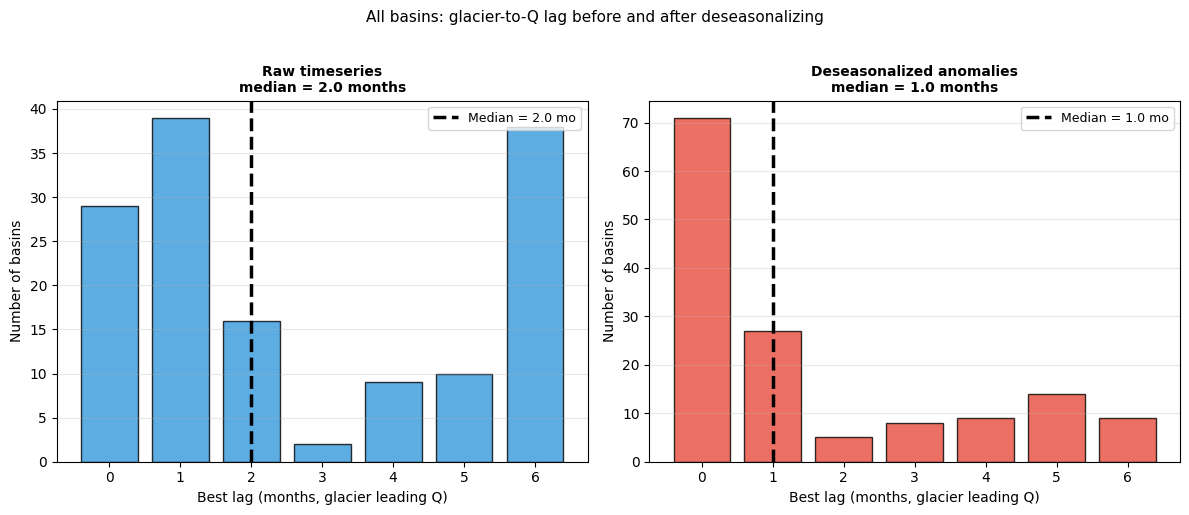


Lag analysis by cluster (raw vs deseasonalized, CR2MET):
Cluster n    Raw median  Des median  Interpretation
------------------------------------------------------------
OT3       3         1.0         1.0 genuine delay
DA1      22         1.5         0.0 aliasing likely
DA2      12         2.0         1.0 genuine delay
DA3      16         3.0         0.0 aliasing likely
WA1      44         5.5         0.0 aliasing likely
WA2      30         1.0         1.0 genuine delay
WA3       7         2.0         1.0 genuine delay
WA4       7         1.0         1.0 genuine delay
WA6       2         0.5         6.0 unclear

Note: WA1 specifically was the original motivating case (5.5-month raw lag,
confirmed here as seasonal aliasing -- see WA1 row above).


In [31]:
print('Deseasonalized lag analysis -- all basins (CR2MET)')
print('=' * 60)

def deseasonalize(series, months):
    anom = series.copy().astype(float)
    for mo in range(1, 13):
        mask = months == mo
        if mask.sum() > 0:
            anom[mask] -= anom[mask].mean()
    return anom

def best_lag_pearson(x, y, max_lag=6):
    best_r, best_lag = 0, 0
    for lag in range(0, max_lag + 1):
        if lag == 0:
            valid = ~(np.isnan(x) | np.isnan(y))
            if valid.sum() < 10:
                continue
            r, _ = stats.pearsonr(x[valid], y[valid])
        else:
            xlag, ylag = x[:-lag], y[lag:]
            valid = ~(np.isnan(xlag) | np.isnan(ylag))
            if valid.sum() < 10:
                continue
            r, _ = stats.pearsonr(xlag[valid], ylag[valid])
        if abs(r) > abs(best_r):
            best_r, best_lag = r, lag
    return best_lag, best_r

best_lags_raw, best_lags_deseas, results_by_gauge = [], [], []

for gauge_id, info in GAUGE_INFO_FRAC.items():
    res = RESULTS['CR2MET'].get(gauge_id)
    if res is None:
        continue
    m  = res['monthly']
    cy = res.get('complete_years', YEARS)

    mc = (m[m['year'].isin(cy)].sort_values(['year','month']).reset_index(drop=True))
    mc = mc.dropna(subset=['q_m3_mon']).reset_index(drop=True)   # critical: drop NaN Q rows first

    if len(mc) < 36:
        continue

    glac   = mc['glacier_runoff_m3'].values.astype(float)
    q      = mc['q_m3_mon'].values.astype(float)
    months = mc['month'].values

    lag_raw, r_raw = best_lag_pearson(glac, q)
    glac_a = deseasonalize(glac, months)
    q_a    = deseasonalize(q, months)
    lag_des, r_des = best_lag_pearson(glac_a, q_a)

    best_lags_raw.append(lag_raw)
    best_lags_deseas.append(lag_des)
    results_by_gauge.append({
        'gauge_id': gauge_id, 'cluster': info['clusters'][0], 'name': info['gauge_name'][:35],
        'n_months': len(mc), 'lag_raw': lag_raw, 'r_raw': r_raw,
        'lag_des': lag_des, 'r_des': r_des, 'changed': abs(lag_raw - lag_des) >= 2,
    })

df_lag_deseas = pd.DataFrame(results_by_gauge)
df_lag_deseas.to_csv(f'{DROUGHT_DIR}/lag_deseasonalized_all_basins.csv', index=False)

med_raw = np.median(best_lags_raw)
med_des = np.median(best_lags_deseas)

print(f'National (all basins): median raw lag = {med_raw:.1f} months')
print(f'National (all basins): median deseasonalized lag = {med_des:.1f} months')
n_changed = df_lag_deseas['changed'].sum()
print(f'{n_changed} of {len(df_lag_deseas)} basins changed lag by >=2 months after deseasonalizing')
print()

if med_des < med_raw - 1:
    print('INTERPRETATION: median lag dropped substantially after deseasonalizing --')
    print('a meaningful share of the raw lag nationally is seasonal aliasing.')
elif abs(med_des - med_raw) <= 1:
    print('INTERPRETATION: national median lag is similar before/after deseasonalizing --')
    print('genuine routing delay dominates nationally.')
else:
    print('INTERPRETATION: unusual national result -- inspect per-cluster breakdown below.')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, lags, title, color in [
    (axes[0], best_lags_raw, f'Raw timeseries\nmedian = {med_raw:.1f} months', '#3498db'),
    (axes[1], best_lags_deseas, f'Deseasonalized anomalies\nmedian = {med_des:.1f} months', '#e74c3c'),
]:
    counts = [lags.count(l) for l in range(0, 7)]
    ax.bar(range(0, 7), counts, color=color, edgecolor='k', alpha=0.8)
    ax.axvline(np.median(lags), color='k', lw=2.5, ls='--', label=f'Median = {np.median(lags):.1f} mo')
    ax.set_xlabel('Best lag (months, glacier leading Q)', fontsize=10)
    ax.set_ylabel('Number of basins', fontsize=10)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.legend(fontsize=9); ax.set_xticks(range(0, 7)); ax.grid(True, alpha=0.3, axis='y')

fig.suptitle('All basins: glacier-to-Q lag before and after deseasonalizing', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/lag_deseasonalized_all_basins.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print('Lag analysis by cluster (raw vs deseasonalized, CR2MET):')
print(f'{"Cluster":6s} {"n":4s} {"Raw median":11s} {"Des median":11s} {"Interpretation"}')
print('-' * 60)

for cl in CLUSTERS:
    cl_sub = df_lag_deseas[df_lag_deseas['cluster'] == cl]
    if len(cl_sub) == 0:
        continue
    med_r, med_d = cl_sub['lag_raw'].median(), cl_sub['lag_des'].median()
    interp = 'aliasing likely' if med_d < med_r - 1 else 'genuine delay' if abs(med_d - med_r) <= 1 else 'unclear'
    print(f'{cl:6s} {len(cl_sub):4d} {med_r:11.1f} {med_d:11.1f} {interp}')

print()
print('Note: WA1 specifically was the original motivating case (5.5-month raw lag,')
print('confirmed here as seasonal aliasing -- see WA1 row above).')


### Apply deseasonalized lag correction to glacier fractions

Distinct from the exponential routing above -- applies a simple integer
month shift based on the empirically derived deseasonalized lag (1-month
genuine lag confirmed for DA2/WA2/WA3/WA4; WA1's 5.5-month raw lag
confirmed as seasonal aliasing and NOT applied).

In [32]:
DESEAS_LAG = {'OT3': 0, 'DA1': 0, 'DA2': 1, 'DA3': 0, 'WA1': 0,
              'WA2': 1, 'WA3': 1, 'WA4': 1, 'WA5': 0, 'WA6': 0}

FEB_APR, OCT_MAR, MARCH = [2, 3, 4], [10, 11, 12, 1, 2, 3], [3]

print('Computing lag-corrected glacier fractions (1-month shift for DA2, WA2, WA3, WA4)')

lag_corr_records = []

for gauge_id, info in GAUGE_INFO_FRAC.items():
    cl  = info['clusters'][0]
    lag = DESEAS_LAG.get(cl, 0)

    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        res = RESULTS[ds_name].get(gauge_id)
        if res is None:
            continue
        m  = res['monthly']
        cy = res.get('complete_years', YEARS)

        mc = (m[m['year'].isin(cy)].sort_values(['year','month']).dropna(subset=['q_m3_mon']).reset_index(drop=True))
        if len(mc) < 12:
            continue

        mc['glac_shifted'] = mc['glacier_runoff_m3'].shift(lag) if lag > 0 else mc['glacier_runoff_m3']
        mc = mc.dropna(subset=['glac_shifted', 'q_m3_mon'])
        mc = mc[mc['q_m3_mon'] > 0]
        if len(mc) < 12:
            continue

        def season_frac(months):
            sub = mc[mc['month'].isin(months)]
            if len(sub) == 0:
                return np.nan, np.nan
            ann = sub.groupby('year').agg(glac_raw=('glacier_runoff_m3', 'sum'),
                                          glac_shifted=('glac_shifted', 'sum'),
                                          q=('q_m3_mon', 'sum')).reset_index()
            ann = ann[ann['q'] > 0]
            if len(ann) == 0:
                return np.nan, np.nan
            return (ann['glac_raw']/ann['q']).mean()*100, (ann['glac_shifted']/ann['q']).mean()*100

        ann_raw, ann_shift = season_frac(list(range(1,13)))
        mar_raw, mar_shift = season_frac(MARCH)

        lag_corr_records.append({
            'gauge_id': gauge_id, 'cluster': cl, 'lag_applied': lag, 'dataset': ds_name,
            'ann_raw': ann_raw, 'ann_shifted': ann_shift,
            'mar_raw': mar_raw, 'mar_shifted': mar_shift,
        })

df_lag_corr = pd.DataFrame(lag_corr_records)
print(f'Records: {len(df_lag_corr):,}')

print()
print('Lag-corrected vs raw fractions (CR2MET, cluster means):')
print(f'{"Cluster":6s} {"lag":4s} {"Ann raw%":9s} {"Ann shift%":11s} {"Mar raw%":9s} {"Mar shift%":11s}')
print('-' * 60)

cr2 = df_lag_corr[df_lag_corr['dataset'] == 'CR2MET']
for cl in CLUSTERS:
    sub = cr2[cr2['cluster'] == cl]
    if len(sub) == 0:
        continue
    lag = DESEAS_LAG.get(cl, 0)
    sub_clean = sub[sub['mar_raw'] <= 100]
    print(f'{cl:6s} {lag:4d} {sub_clean["ann_raw"].mean():9.2f} {sub_clean["ann_shifted"].mean():11.2f} '
          f'{sub_clean["mar_raw"].mean():9.2f} {sub_clean["mar_shifted"].mean():11.2f}')

df_lag_corr.to_csv(f'{DROUGHT_DIR}/glacier_fractions_lag_corrected.csv', index=False)
print(f'Saved: {DROUGHT_DIR}/glacier_fractions_lag_corrected.csv')


Computing lag-corrected glacier fractions (1-month shift for DA2, WA2, WA3, WA4)
Records: 429

Lag-corrected vs raw fractions (CR2MET, cluster means):
Cluster lag  Ann raw%  Ann shift%  Mar raw%  Mar shift% 
------------------------------------------------------------
OT3       0      3.01        3.01      7.17        7.17
DA1       0     15.02       15.02     25.90       25.90
DA2       1     14.79       15.23     41.47       73.87
DA3       0      3.38        3.38     10.41       10.41
WA1       0      2.15        2.15     13.02       13.02
WA2       1      4.95        5.08      9.40       12.46
WA3       1     20.48       20.74     23.25       27.78
WA4       1      8.36        8.58     11.60       20.80
WA6       0      0.46        0.46      1.16        1.16
Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/megadrought_analysis/all_glacierized/glacier_fractions_lag_corrected.csv


### Mass balance trend vs. runoff trend -- the "bank account" test

SMB from `mb.csv` (OGGM calibrated, mm w.e./yr per glacier per year),
aggregated to basin level via area-weighted mean.

In [33]:
from scipy.stats import linregress

print('Computing annual melt, precip-on-glacier, and Q per basin...')

trend_records = []

for gauge_id, info in GAUGE_INFO_FRAC.items():
    cy = info['complete_years']

    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        res = RESULTS[ds_name].get(gauge_id)
        if res is None:
            continue
        m = res['monthly']
        mc = m[m['year'].isin(cy)]

        ann = mc.groupby('year').agg(
            melt_m3=('melt_on_glacier_m3', 'sum'), liq_m3=('liq_prcp_on_glacier_m3', 'sum'),
            glac_m3=('glacier_runoff_m3', 'sum'), q_m3=('q_m3_mon', 'sum')).reset_index()
        ann = ann[ann['q_m3'] > 0]
        if len(ann) < 10:
            continue

        def trend(y_series, x_years):
            slope, intercept, r, p, se = linregress(x_years, y_series)
            mean_val = y_series.mean()
            pct_per_yr = (slope / mean_val * 100) if mean_val != 0 else np.nan
            cv = (y_series.std() / mean_val) if mean_val != 0 else np.nan
            return slope, p, pct_per_yr, cv

        yrs = ann['year'].values
        melt_slope, melt_p, melt_pct, melt_cv = trend(ann['melt_m3'].values, yrs)
        liq_slope,  liq_p,  liq_pct,  liq_cv  = trend(ann['liq_m3'].values,  yrs)
        glac_slope, glac_p, glac_pct, glac_cv = trend(ann['glac_m3'].values, yrs)
        q_slope,    q_p,    q_pct,    q_cv    = trend(ann['q_m3'].values,    yrs)

        trend_records.append({
            'gauge_id': gauge_id, 'cluster': info['clusters'][0], 'lat': info['cen_lat'],
            'dataset': ds_name, 'n_years': len(ann),
            'melt_pct_per_yr': melt_pct, 'melt_p': melt_p, 'melt_cv': melt_cv,
            'liq_pct_per_yr':  liq_pct,  'liq_p':  liq_p,  'liq_cv':  liq_cv,
            'glac_pct_per_yr': glac_pct, 'glac_p': glac_p, 'glac_cv': glac_cv,
            'q_pct_per_yr':    q_pct,    'q_p':    q_p,    'q_cv':    q_cv,
        })

df_trends = pd.DataFrame(trend_records)
df_trends.to_csv(f'{DROUGHT_DIR}/melt_precip_trends_by_basin.csv', index=False)
print(f'Trend records: {len(df_trends):,} ({df_trends["gauge_id"].nunique()} basins)')

print()
print('Median annual trend (%/yr) by cluster -- CR2MET (sig% = fraction basins p<0.05)')
print('='*100)
print(f'{"Cluster":6s} {"n":4s} {"Melt %/yr":10s} {"sig%":6s}  {"Precip %/yr":11s} {"sig%":6s}  '
      f'{"Runoff %/yr":11s} {"sig%":6s}  {"Q %/yr":8s} {"sig%":6s}')
print('-'*100)

cr2 = df_trends[df_trends['dataset'] == 'CR2MET']
for cl in CLUSTERS:
    sub = cr2[cr2['cluster'] == cl]
    if len(sub) == 0:
        continue
    n = len(sub)

    def summarize(pct_col, p_col):
        return sub[pct_col].median(), (sub[p_col] < 0.05).mean() * 100

    melt_med, melt_sig = summarize('melt_pct_per_yr', 'melt_p')
    liq_med,  liq_sig  = summarize('liq_pct_per_yr',  'liq_p')
    glac_med, glac_sig = summarize('glac_pct_per_yr', 'glac_p')
    q_med,    q_sig    = summarize('q_pct_per_yr',    'q_p')

    print(f'{cl:6s} {n:4d} {melt_med:+10.2f} {melt_sig:5.0f}%  {liq_med:+11.2f} {liq_sig:5.0f}%  '
          f'{glac_med:+11.2f} {glac_sig:5.0f}%  {q_med:+8.2f} {q_sig:5.0f}%')

print()
print('INTERPRETATION: Melt %/yr > 0 significant = ice melt volume increasing. Runoff')
print('%/yr near 0 despite melt trending up = "draining the bank account" pattern.')


Computing annual melt, precip-on-glacier, and Q per basin...
Trend records: 423 (141 basins)

Median annual trend (%/yr) by cluster -- CR2MET (sig% = fraction basins p<0.05)
Cluster n    Melt %/yr  sig%    Precip %/yr sig%    Runoff %/yr sig%    Q %/yr   sig%  
----------------------------------------------------------------------------------------------------
OT3       3      -1.34     0%        -2.05     0%        -1.40     0%     -1.72    33%
DA1      22      +2.99    50%        +1.80     0%        +2.87    41%     -3.28    32%
DA2      12      +1.79    67%        -1.85    25%        +1.49    42%     -5.78    92%
DA3      16      -0.15    31%        -2.58    12%        -0.57    12%     -6.07   100%
WA1      44      +0.42     7%        -1.61     2%        -0.13     2%     -3.86    82%
WA2      28      +0.34     7%        -0.62     7%        -0.11    11%     -1.90    39%
WA3       7      -0.22    43%        +0.70    14%        +0.56    57%     +0.07     0%
WA4       7      +0.10     0

### Supporting evidence: melt/precip-on-glacier trend table (Noah)

The per-cluster trend table below is the evidence base for the
mass-balance "bank account" classification just above -- it shows,
per cluster, the median annual trend (%/yr) and significance share for
ice melt, precip-on-glacier, total glacier runoff, and streamflow.

In [34]:
from scipy.stats import linregress
rgi_areas = pd.read_csv(RGI_PATH)[['RGIId', 'Area']].set_index('RGIId')

print('Loading per-glacier SMB (mb.csv) across all clusters/datasets...')

smb_by_glacier = {}

for ds_name in ['CR2MET', 'ERA5', 'CRU']:
    smb_by_glacier[ds_name] = {}
    for cl in CLUSTERS:
        mb_file = f'{OUTPUT_ROOT}/{ds_name}/{cl}/mb.csv'
        if not os.path.exists(mb_file):
            continue
        mb_df = pd.read_csv(mb_file).set_index('rgi_id')
        year_cols = mb_df.columns[:20]
        for rgi_id, row in mb_df.iterrows():
            vals = row[year_cols].values.astype(float)
            if np.all(np.isnan(vals)):
                continue
            smb_by_glacier[ds_name][rgi_id] = pd.Series(vals, index=YEARS)

for ds_name in smb_by_glacier:
    print(f'  {ds_name}: {len(smb_by_glacier[ds_name])} glaciers with SMB')

print('Computing basin-level annual SMB (area-weighted)...')

smb_trend_records = []

for gauge_id, info in GAUGE_INFO_FRAC.items():
    rgi_ids = info.get('rgi_ids', [])
    if not rgi_ids:
        continue

    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        avail = [r for r in rgi_ids if r in smb_by_glacier[ds_name]]
        avail = [r for r in avail if r in rgi_areas.index]
        if len(avail) == 0:
            continue

        weights = rgi_areas.loc[avail, 'Area'].values
        smb_matrix = np.array([smb_by_glacier[ds_name][r].values for r in avail])

        ann_smb = np.average(smb_matrix, axis=0, weights=weights)
        ann_smb = pd.Series(ann_smb, index=YEARS).dropna()

        if len(ann_smb) < 10:
            continue

        slope, intercept, r, p, se = linregress(ann_smb.index.values, ann_smb.values)

        smb_trend_records.append({
            'gauge_id': gauge_id, 'cluster': info['clusters'][0], 'lat': info['cen_lat'],
            'dataset': ds_name, 'n_glaciers': len(avail), 'n_years': len(ann_smb),
            'smb_mean': ann_smb.mean(), 'smb_slope': slope, 'smb_p': p,
        })

df_smb_trends = pd.DataFrame(smb_trend_records)
df_smb_trends.to_csv(f'{DROUGHT_DIR}/smb_trends_by_basin.csv', index=False)
print(f'SMB trend records: {len(df_smb_trends):,} ({df_smb_trends["gauge_id"].nunique()} basins)')

merged_trends = df_trends.merge(
    df_smb_trends[['gauge_id','dataset','smb_mean','smb_slope','smb_p']], on=['gauge_id','dataset'], how='inner')

print()
print('SMB trend vs. glacier runoff trend by cluster -- CR2MET')
print('='*95)
print(f'{"Cluster":6s} {"n":4s} {"SMB mean":10s} {"SMB slope":11s} {"sig%":6s}  {"Runoff %/yr":11s} {"sig%":6s}  {"Pattern"}')
print('-'*95)

cr2_merged = merged_trends[merged_trends['dataset'] == 'CR2MET']
for cl in CLUSTERS:
    sub = cr2_merged[cr2_merged['cluster'] == cl]
    if len(sub) == 0:
        continue
    n = len(sub)
    smb_mean_med  = sub['smb_mean'].median()
    smb_slope_med = sub['smb_slope'].median()
    smb_sig       = (sub['smb_p'] < 0.05).mean() * 100
    glac_med      = sub['glac_pct_per_yr'].median()
    glac_sig      = (sub['glac_p'] < 0.05).mean() * 100

    if smb_slope_med < 0 and smb_sig > 30 and abs(glac_med) < 1.5:
        pattern = 'BANK ACCOUNT (MB down, runoff flat)'
    elif smb_slope_med < 0 and glac_med > 0:
        pattern = 'MB down, runoff UP (partial buffering)'
    elif smb_slope_med < 0 and glac_med < 0:
        pattern = 'MB down, runoff down (declining together)'
    else:
        pattern = '-'

    print(f'{cl:6s} {n:4d} {smb_mean_med:10.1f} {smb_slope_med:11.2f} {smb_sig:5.0f}%  '
          f'{glac_med:+11.2f} {glac_sig:5.0f}%  {pattern}')


Loading per-glacier SMB (mb.csv) across all clusters/datasets...
  CR2MET: 13123 glaciers with SMB
  ERA5: 13160 glaciers with SMB
  CRU: 13099 glaciers with SMB
Computing basin-level annual SMB (area-weighted)...
SMB trend records: 429 (143 basins)

SMB trend vs. glacier runoff trend by cluster -- CR2MET
Cluster n    SMB mean   SMB slope   sig%    Runoff %/yr sig%    Pattern
-----------------------------------------------------------------------------------------------
OT3       3     -101.6      -12.78     0%        -1.40     0%  MB down, runoff down (declining together)
DA1      22     -152.1      -32.64    91%        +2.87    41%  MB down, runoff UP (partial buffering)
DA2      12     -385.5      -51.07   100%        +1.49    42%  BANK ACCOUNT (MB down, runoff flat)
DA3      16     -416.0      -72.71   100%        -0.57    12%  BANK ACCOUNT (MB down, runoff flat)
WA1      44     -372.8      -66.40   100%        -0.13     2%  BANK ACCOUNT (MB down, runoff flat)
WA2      28     -374.

## Peak water indicator

Peak water = year of maximum annual glacier runoff before long-term
decline. Identifies basins where glacier melt volume is already trending
downward over 2000-2019 (a signal of post-peak-water trajectory), plus
a pre/post-drought trend-slope split.

In [35]:
print('Peak water indicator: glacier melt volume trend 2000-2019')
print('=' * 65)

pw_records = []

for gauge_id, info in GAUGE_INFO_FRAC.items():
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        res = RESULTS[ds_name].get(gauge_id)
        if res is None:
            continue
        m  = res['monthly']
        cy = res.get('complete_years', YEARS)

        ann_melt = (m[m['year'].isin(cy)].groupby('year')['glacier_runoff_m3'].sum())
        if len(ann_melt) < 8:
            continue

        x = ann_melt.index.values.astype(float)
        y = ann_melt.values
        slope, _, r, p, _ = stats.linregress(x, y)

        pw_records.append({
            'gauge_id': gauge_id, 'gauge_name': info['gauge_name'][:35], 'lat': info['cen_lat'],
            'cluster': info['clusters'][0], 'glacier_area_km2': info['glacier_area_km2'],
            'dataset': ds_name, 'slope_m3_yr': slope, 'r': r, 'p': p,
            'sig': p < 0.05, 'declining': slope < 0, 'sig_declining': p < 0.05 and slope < 0,
        })

df_pw = pd.DataFrame(pw_records)

for ds_name in ['CR2MET', 'ERA5', 'CRU']:
    sub = df_pw[df_pw['dataset'] == ds_name]
    dec = sub[sub['sig_declining']]
    inc = sub[sub['sig'] & ~sub['declining']]
    print(f'{ds_name}: {len(dec)} basins declining, {len(inc)} basins increasing, {len(sub)-len(dec)-len(inc)} no trend')

sig_dec = (df_pw[df_pw['sig_declining']].groupby('gauge_id')['dataset'].count())
robust_dec = sig_dec[sig_dec == 3].index.tolist()
print(f'Robust declining melt volume (all 3 datasets): n = {len(robust_dec)}')

if robust_dec:
    rd_df = (df_pw[(df_pw['gauge_id'].isin(robust_dec)) & (df_pw['dataset'] == 'CR2MET')].sort_values('slope_m3_yr'))
    for _, row in rd_df.iterrows():
        print(f'  {row["gauge_id"]:10s} {row["gauge_name"]:35s} slope={row["slope_m3_yr"]:+.0f} m3/yr  '
              f'cluster={row["cluster"]}  lat={row["lat"]:.1f}S  glac={row["glacier_area_km2"]:.1f} km2')

sig_inc = (df_pw[df_pw['sig'] & ~df_pw['declining']].groupby('gauge_id')['dataset'].count())
robust_inc = sig_inc[sig_inc == 3].index.tolist()
print(f'Robust increasing melt volume (all 3 datasets, n={len(robust_inc)}) -- still approaching peak water')

print()
print('Peak water status by cluster (CR2MET):')
print(f'{"Cluster":6s} {"n":4s} {"% declining":12s} {"% increasing":13s} {"% no trend"}')
print('-' * 45)
cr2_pw = df_pw[df_pw['dataset'] == 'CR2MET']
for cl in CLUSTERS:
    cl_df = cr2_pw[cr2_pw['cluster'] == cl]
    if len(cl_df) == 0:
        continue
    pct_dec = cl_df['sig_declining'].mean() * 100
    pct_inc = (cl_df['sig'] & ~cl_df['declining']).mean() * 100
    print(f'{cl:6s} {len(cl_df):4d} {pct_dec:12.0f}% {pct_inc:13.0f}% {100-pct_dec-pct_inc:.0f}%')

print()
print('Trend comparison: 2000-2009 (baseline) vs 2010-2019 (drought)')
for period_name, years in [('2000-2009', range(2000,2010)), ('2010-2019', range(2010,2020))]:
    slopes, sig_inc_ct, n_total = [], 0, 0
    for gauge_id, info in GAUGE_INFO_FRAC.items():
        res = RESULTS['CR2MET'].get(gauge_id)
        if res is None:
            continue
        m  = res['monthly']
        cy = [y for y in res.get('complete_years', YEARS) if y in years]
        if len(cy) < 5:
            continue
        ann = (m[m['year'].isin(cy)].groupby('year').agg(glac=('glacier_runoff_m3','sum'), q=('q_m3_mon','sum')))
        ann = ann[ann['q'] > 0]
        ann['frac'] = ann['glac'] / ann['q'] * 100
        if len(ann) < 5:
            continue
        x = ann.index.values.astype(float)
        y = ann['frac'].values
        slope, _, r, p, _ = stats.linregress(x, y)
        slopes.append(slope)
        if p < 0.05 and slope > 0:
            sig_inc_ct += 1
        n_total += 1

    print(f'  {period_name}: n={n_total}, median slope={np.median(slopes):+.4f} pp/yr, '
          f'sig increasing={sig_inc_ct} ({sig_inc_ct/n_total*100:.0f}%)')


Peak water indicator: glacier melt volume trend 2000-2019
CR2MET: 8 basins declining, 17 basins increasing, 118 no trend
ERA5: 6 basins declining, 9 basins increasing, 128 no trend
CRU: 13 basins declining, 7 basins increasing, 123 no trend
Robust declining melt volume (all 3 datasets): n = 4
  12448001   Rio Grande En Isla Riesco           slope=-151553 m3/yr  cluster=WA6  lat=-52.9S  glac=2.6 km2
  7306001    Rio Cipreses En Dasague Laguna La I slope=-90742 m3/yr  cluster=WA1  lat=-35.6S  glac=1.4 km2
  7104002    Rio Teno Despues De Junta Con Claro slope=-78468 m3/yr  cluster=DA3  lat=-35.2S  glac=1.3 km2
  11141001   Rio Cisnes En Estancia Rio Cisnes   slope=-1027 m3/yr  cluster=WA2  lat=-44.7S  glac=0.0 km2
Robust increasing melt volume (all 3 datasets, n=0) -- still approaching peak water

Peak water status by cluster (CR2MET):
Cluster n    % declining  % increasing  % no trend
---------------------------------------------
OT3       3            0%             0% 100%
DA1      22

### Identify and exclude basins with implausible (>100%) March fractions

March glacier fraction exceeding 100% (glacier melt volume larger than
total measured streamflow that month) is physically impossible for a
single month and indicates either a streamflow gauging issue or a
melt/routing mismatch in specific small, low-flow basins -- these are
flagged and excluded from March-specific summary statistics rather than
silently distorting cluster means.

In [36]:
print('Basins with March glacier fraction >100% (CR2MET):')
print('=' * 65)

problem_basins = []

for gauge_id, info in GAUGE_INFO_FRAC.items():
    res = RESULTS['CR2MET'].get(gauge_id)
    if res is None:
        continue
    m  = res['monthly']
    cy = res.get('complete_years', YEARS)

    sub = (m[m['year'].isin(cy) & m['month'].isin([3])].dropna(subset=['q_m3_mon']))
    sub = sub[sub['q_m3_mon'] > 0]
    if len(sub) == 0:
        continue

    ann = sub.groupby('year').agg(glac=('glacier_runoff_m3', 'sum'), q=('q_m3_mon', 'sum')).reset_index()
    ann = ann[ann['q'] > 0]
    if len(ann) == 0:
        continue

    ann['frac'] = ann['glac'] / ann['q'] * 100
    mean_frac = ann['frac'].mean()
    n_years_over = (ann['frac'] > 100).sum()
    max_frac = ann['frac'].max()

    if mean_frac > 100 or n_years_over > 0:
        problem_basins.append({
            'gauge_id': gauge_id, 'gauge_name': info['gauge_name'][:40], 'cluster': info['clusters'][0],
            'lat': info['cen_lat'], 'glac_km2': info['glacier_area_km2'],
            'basin_km2': info.get('basin_area_km2', np.nan), 'mean_frac': mean_frac,
            'max_frac': max_frac, 'n_yrs_over': n_years_over, 'n_yrs_total': len(ann),
        })

df_prob = pd.DataFrame(problem_basins).sort_values('mean_frac', ascending=False)
print(f'Total basins with any March year >100%: {len(df_prob)}')

EXCLUDE_MARCH = set(df_prob[df_prob['mean_frac'] > 100]['gauge_id'].tolist())
print(f'Basins excluded from March cluster means (mean >100%): {len(EXCLUDE_MARCH)}')
print(EXCLUDE_MARCH)

print()
print('Revised March fractions by cluster (excluding >100% basins, CR2MET):')
print(f'{"Cluster":6s} {"n excl":7s} {"n used":7s} {"March mean%":12s} {"March median%"}')
print('-' * 50)

for cl in CLUSTERS:
    cl_gauges = [gid for gid, info in GAUGE_INFO_FRAC.items() if info['clusters'][0] == cl]
    fracs, n_excl = [], 0
    for gid in cl_gauges:
        if gid in EXCLUDE_MARCH:
            n_excl += 1
            continue
        res = RESULTS['CR2MET'].get(gid)
        if res is None:
            continue
        m  = res['monthly']
        cy = res.get('complete_years', YEARS)
        sub = (m[m['year'].isin(cy) & m['month'].isin([3])].dropna(subset=['q_m3_mon']))
        sub = sub[sub['q_m3_mon'] > 0]
        if len(sub) == 0:
            continue
        ann = sub.groupby('year').agg(glac=('glacier_runoff_m3','sum'), q=('q_m3_mon','sum')).reset_index()
        ann = ann[ann['q'] > 0]
        frac = (ann['glac']/ann['q']).mean()*100
        if not np.isnan(frac) and frac <= 100:
            fracs.append(frac)

    if fracs:
        print(f'{cl:6s} {n_excl:7d} {len(fracs):7d} {np.mean(fracs):12.1f} {np.median(fracs):.1f}%')
    else:
        print(f'{cl:6s} {n_excl:7d} {0:7d} n/a')


Basins with March glacier fraction >100% (CR2MET):
Total basins with any March year >100%: 27
Basins excluded from March cluster means (mean >100%): 14
{'5706001', '6008005', '7317003', '3421001', '5403002', '5406001', '7317005', '3022001', '1020003', '7306001', '7321002', '5702001', '3430001', '6035001'}

Revised March fractions by cluster (excluding >100% basins, CR2MET):
Cluster n excl  n used  March mean%  March median%
--------------------------------------------------
OT3          1       2          7.2 7.2%
DA1          3      19         25.9 21.1%
DA2          3       9         41.5 32.7%
DA3          6      10         10.4 4.3%
WA1          1      43         13.0 10.3%
WA2          0      30          9.4 6.1%
WA3          0       7         23.3 30.7%
WA4          0       7         11.6 4.7%
WA5          0       0 n/a
WA6          0       2          1.2 1.2%


## Addressing Noah's ideas, continued: replication check and mass-balance decomposition

(The melt/precip trend table and mass-balance "bank account" test are
above, right after the lag analysis, since they build directly on it.
This continues with a literature replication check and a finer
accumulation-vs-ablation decomposition of the mass-balance trend.)

### Direct replication check -- Ayala et al. framing (Maipo)

Ayala et al. compared period MEANS (2000-2009 vs 2010-2019), not a
continuous linear trend. Reproduces that exact comparison for Rio Maipo
En El Manzano to check consistency with the published "runoff almost
unaltered, sustained by ~10% ice volume loss" finding, plus all of DA2
for context.

In [37]:
MAIPO_GAUGE = '5710001'

def period_mean_check(gauge_id, dataset='CR2MET'):
    info = GAUGE_INFO_FRAC.get(gauge_id)
    if info is None:
        return None
    cy = info['complete_years']
    res = RESULTS[dataset].get(gauge_id)
    if res is None:
        return None
    m = res['monthly']
    mc = m[m['year'].isin(cy)]

    ann = mc.groupby('year').agg(melt_m3=('melt_on_glacier_m3', 'sum'), liq_m3=('liq_prcp_on_glacier_m3', 'sum'),
                                 glac_m3=('glacier_runoff_m3', 'sum'), q_m3=('q_m3_mon', 'sum')).reset_index()
    ann = ann[ann['q_m3'] > 0]

    base = ann[ann['year'].isin(range(2000,2010))]
    drgt = ann[ann['year'].isin(range(2010,2020))]
    if len(base) == 0 or len(drgt) == 0:
        return None

    def pct_chg(col):
        b, d = base[col].mean(), drgt[col].mean()
        return b, d, (d - b) / b * 100 if b != 0 else np.nan

    return {'gauge_id': gauge_id, 'melt': pct_chg('melt_m3'), 'liq': pct_chg('liq_m3'),
            'runoff': pct_chg('glac_m3'), 'q': pct_chg('q_m3')}

print('Period-mean comparison (Ayala-style): 2000-2009 vs 2010-2019')
print('='*70)

result = period_mean_check(MAIPO_GAUGE)
if result:
    print(f'Rio Maipo En El Manzano ({MAIPO_GAUGE}) -- CR2MET')
    for key, label in [('melt','Ice melt'), ('liq','Precip on glacier'), ('runoff','Total glacier runoff'), ('q','Q')]:
        b, d, pct = result[key]
        print(f'  {label:22s}  base={b/1e6:8.2f}M  drought={d/1e6:8.2f}M  delta={pct:+.1f}%')
else:
    print(f'No data for {MAIPO_GAUGE}')

print()
print('All DA2 basins, individually, for context:')
print(f'{"gauge_id":12s} {"melt d%":9s} {"liq d%":8s} {"runoff d%":10s} {"Q d%"}')
print('-'*55)
for gid, info in GAUGE_INFO_FRAC.items():
    if info['clusters'][0] != 'DA2':
        continue
    r = period_mean_check(gid)
    if r is None:
        continue
    print(f'{gid:12s} {r["melt"][2]:+8.1f}% {r["liq"][2]:+7.1f}% {r["runoff"][2]:+9.1f}% {r["q"][2]:+.1f}%')


Period-mean comparison (Ayala-style): 2000-2009 vs 2010-2019
Rio Maipo En El Manzano (5710001) -- CR2MET
  Ice melt                base=  332.78M  drought=  381.88M  delta=+14.8%
  Precip on glacier       base=   46.11M  drought=   35.89M  delta=-22.2%
  Total glacier runoff    base=  378.89M  drought=  417.77M  delta=+10.3%
  Q                       base= 3972.71M  drought= 2224.83M  delta=-44.0%

All DA2 basins, individually, for context:
gauge_id     melt d%   liq d%   runoff d%  Q d%
-------------------------------------------------------
5401003         +26.7%   -19.3%     +23.6% -37.8%
5403002         +22.5%   -31.6%     +18.5% -56.5%
5406001         +12.6%   -22.0%     +10.1% -83.6%
5410002         +20.4%   -19.8%     +17.4% -52.5%
5410005         +29.5%   -15.7%     +26.2% -71.6%
5423003          +7.7%   -37.9%      +4.3% -75.4%
5706001          -0.7%   -18.2%      -1.4% -50.5%
5707002         +29.3%    -8.4%     +27.1% -40.0%
5710001         +14.8%   -22.2%     +10.3% -44.0%
5

### Decompose MB trend into accumulation vs. ablation drivers

MB = accumulation (snowfall_on_glacier) - ablation (melt_on_glacier).
Decomposes the CHANGE in MB (2010-2019 vs 2000-2009) into how much is
explained by declining accumulation vs. increasing ablation, using the
same counterfactual approach as the Q-decline-vs-melt-change
decomposition above.

In [39]:
import xarray as xr
print('Extracting annual snowfall_on_glacier and melt_on_glacier per basin (CR2MET)...')

accum_ablat_records = []

for ds_name in ['CR2MET']:
    for cl in CLUSTERS:
        nc_file = f'{OUTPUT_ROOT}/{ds_name}/{cl}/run_output_2000_2019_hydro_TC_{cl}.nc'
        if not os.path.exists(nc_file):
            continue

        ds = xr.open_dataset(nc_file)
        rgi_all = list(ds.rgi_id.values)
        actual_years = ds['time'].values.astype(int).tolist()

        snow_annual = np.nansum(ds['snowfall_on_glacier_monthly'].values, axis=1) / WATER_DENSITY
        melt_annual = np.nansum(ds['melt_on_glacier_monthly'].values, axis=1) / WATER_DENSITY

        if snow_annual.shape[0] != len(actual_years):
            ds.close()
            continue

        for gauge_id, info in GAUGE_INFO_FRAC.items():
            if info['clusters'][0] != cl:
                continue
            rgi_ids = info.get('rgi_ids', [])
            mask_ids = [r for r in rgi_ids if r in rgi_all]
            if not mask_ids:
                continue
            mask = np.isin(rgi_all, mask_ids)

            basin_snow = snow_annual[:, mask].sum(axis=1)
            basin_melt = melt_annual[:, mask].sum(axis=1)

            accum_ablat_records.append({'gauge_id': gauge_id, 'cluster': cl,
                                        'years': actual_years, 'snow_m3': basin_snow, 'melt_m3': basin_melt})

        ds.close()

print(f'Extracted for {len(accum_ablat_records)} basin records')

decomp_mb_records = []

for rec in accum_ablat_records:
    ann = pd.DataFrame({'year': rec['years'], 'snow_m3': rec['snow_m3'], 'melt_m3': rec['melt_m3']})
    base = ann[ann['year'].isin(range(2000, 2010))]
    drgt = ann[ann['year'].isin(range(2010, 2020))]
    if len(base) == 0 or len(drgt) == 0:
        continue

    snow_base, melt_base = base['snow_m3'].mean(), base['melt_m3'].mean()
    mb_base = snow_base - melt_base
    snow_dr, melt_dr = drgt['snow_m3'].mean(), drgt['melt_m3'].mean()
    mb_dr = snow_dr - melt_dr

    delta_mb = mb_dr - mb_base
    if abs(delta_mb) < 1e-6:
        continue

    mb_cf_snow_only = snow_dr   - melt_base
    mb_cf_melt_only = snow_base - melt_dr

    pct_accum_driven = (mb_cf_snow_only - mb_base) / delta_mb * 100
    pct_ablat_driven = (mb_cf_melt_only - mb_base) / delta_mb * 100

    decomp_mb_records.append({
        'gauge_id': rec['gauge_id'], 'cluster': rec['cluster'],
        'snow_chg_pct': (snow_dr - snow_base) / snow_base * 100 if snow_base > 0 else np.nan,
        'melt_chg_pct': (melt_dr - melt_base) / melt_base * 100 if melt_base > 0 else np.nan,
        'delta_mb_m3': delta_mb,
        'pct_accum_driven': np.clip(pct_accum_driven, -200, 200),
        'pct_ablat_driven': np.clip(pct_ablat_driven, -200, 200),
    })

df_mb_decomp = pd.DataFrame(decomp_mb_records)
df_mb_decomp.to_csv(f'{DROUGHT_DIR}/mb_decomposition_by_basin.csv', index=False)

print()
print('MB change decomposition by cluster (2010-2019 vs 2000-2009), only worsening-MB basins')
print('='*80)
print(f'{"Cluster":6s} {"n":4s} {"Snow d%":9s} {"Melt d%":9s}  {"% due to less accum":19s} {"% due to more ablat"}')
print('-'*80)

for cl in CLUSTERS:
    sub = df_mb_decomp[(df_mb_decomp['cluster'] == cl) & (df_mb_decomp['delta_mb_m3'] < 0)]
    if len(sub) == 0:
        continue
    n = len(sub)
    print(f'{cl:6s} {n:4d} {sub["snow_chg_pct"].median():+8.1f}% {sub["melt_chg_pct"].median():+8.1f}%  '
          f'{sub["pct_accum_driven"].median():18.1f}%  {sub["pct_ablat_driven"].median():18.1f}%')


Extracting annual snowfall_on_glacier and melt_on_glacier per basin (CR2MET)...
Extracted for 143 basin records

MB change decomposition by cluster (2010-2019 vs 2000-2009), only worsening-MB basins
Cluster n    Snow d%   Melt d%    % due to less accum % due to more ablat
--------------------------------------------------------------------------------
OT3       3     -9.1%     +1.5%                87.0%                13.0%
DA1      22     -9.3%    +48.0%                16.0%                84.0%
DA2      12    -45.8%    +21.9%                65.9%                34.1%
DA3      16    -49.8%    -14.9%               153.3%               -53.3%
WA1      44    -25.4%     +3.8%                86.5%                13.5%
WA2      22    -11.6%     +2.1%                78.4%                21.6%
WA3       4     +3.6%     +9.6%               -33.9%               133.9%
WA4       5     +2.3%     +3.7%               -89.9%               189.9%
WA6       1     -1.9%     +3.8%                36.8%  

## Sanity checks (kept for reference, not part of the main analysis flow)

The two cells below (mu_star comparison, seasonal-definition test) are
useful methodological sanity checks but don't feed into the drought/
recession/aridity/lag narrative above -- kept at the end for reference.

## Ale's question: mu_star (degree-day factor) comparison across datasets and clusters

In [40]:
import json as jsonlib

def load_mustar_cluster(ds_name, cluster):
    base = f'{OUTPUT_ROOT}/{ds_name}/{cluster}/per_glacier'
    if not os.path.exists(base):
        return np.nan, 0
    mu_vals = []
    for root, dirs, files in os.walk(base):
        for fname in files:
            if fname == 'local_mustar.json':
                try:
                    with open(os.path.join(root, fname)) as f:
                        d = jsonlib.load(f)
                    val = d.get('mu_star_glacierwide', None)
                    if val is not None and not np.isnan(float(val)):
                        mu_vals.append(float(val))
                except Exception:
                    pass
    if not mu_vals:
        return np.nan, 0
    return np.median(mu_vals), len(mu_vals)

print('Loading mu_star_glacierwide for all clusters and datasets...')
print('(This will take a few minutes -- reading one JSON per glacier)')
print()

mustar_results = {}
for ds_name in ['CR2MET', 'ERA5', 'CRU']:
    mustar_results[ds_name] = {}
    for cl in CLUSTERS:
        med, n = load_mustar_cluster(ds_name, cl)
        mustar_results[ds_name][cl] = med
        print(f'  {ds_name} {cl}: median mu* = {med:.2f} mm C-1 month-1 (n={n} glaciers)')
    print()

print('Median mu* (mm C-1 month-1) by cluster and dataset:')
print(f'{"Cluster":6s}  {"CR2MET":10s}  {"ERA5":10s}  {"CRU":10s}  {"ERA5/CR2":10s}  {"CRU/CR2"}')
print('-' * 65)
for cl in CLUSTERS:
    cr2 = mustar_results['CR2MET'].get(cl, np.nan)
    era = mustar_results['ERA5'].get(cl, np.nan)
    cru = mustar_results['CRU'].get(cl, np.nan)
    r_era = era/cr2 if cr2 > 0 else np.nan
    r_cru = cru/cr2 if cr2 > 0 else np.nan
    print(f'{cl:6s}  {cr2:10.2f}  {era:10.2f}  {cru:10.2f}  {r_era:10.2f}  {r_cru:.2f}')

print()
print('mu* in daily units (mm d-1 C-1, divide monthly by 30.4):')
print('Literature range: 3-10 mm d-1 C-1 (Hock, 2003)')
print(f'{"Cluster":6s}  {"CR2MET":10s}  {"ERA5":10s}  {"CRU":10s}')
print('-' * 40)
for cl in CLUSTERS:
    cr2 = mustar_results['CR2MET'].get(cl, np.nan) / 30.4
    era = mustar_results['ERA5'].get(cl, np.nan)   / 30.4
    cru = mustar_results['CRU'].get(cl, np.nan)    / 30.4
    print(f'{cl:6s}  {cr2:10.3f}  {era:10.3f}  {cru:10.3f}')


Loading mu_star_glacierwide for all clusters and datasets...
(This will take a few minutes -- reading one JSON per glacier)

  CR2MET OT3: median mu* = 528.74 mm C-1 month-1 (n=34 glaciers)
  CR2MET DA1: median mu* = 442.72 mm C-1 month-1 (n=421 glaciers)
  CR2MET DA2: median mu* = 106.33 mm C-1 month-1 (n=200 glaciers)
  CR2MET DA3: median mu* = 50.70 mm C-1 month-1 (n=409 glaciers)
  CR2MET WA1: median mu* = 33.68 mm C-1 month-1 (n=672 glaciers)
  CR2MET WA2: median mu* = 56.81 mm C-1 month-1 (n=2919 glaciers)
  CR2MET WA3: median mu* = 91.46 mm C-1 month-1 (n=447 glaciers)
  CR2MET WA4: median mu* = 70.47 mm C-1 month-1 (n=4716 glaciers)
  CR2MET WA5: median mu* = 101.27 mm C-1 month-1 (n=709 glaciers)
  CR2MET WA6: median mu* = 84.13 mm C-1 month-1 (n=2633 glaciers)

  ERA5 OT3: median mu* = 558.27 mm C-1 month-1 (n=34 glaciers)
  ERA5 DA1: median mu* = 522.70 mm C-1 month-1 (n=422 glaciers)
  ERA5 DA2: median mu* = 541.26 mm C-1 month-1 (n=200 glaciers)
  ERA5 DA3: median mu* = 17

## What is "summer"? Testing seasonal definitions

Compares Annual, Ablation (Oct-Mar), Summer (Feb-Apr), February, and
March glacier fractions. Finding: peak ablation falls somewhere between
March and April, not DJF/JFM -- suggests using **MMA (Mar-Apr-May)** or
similar rather than the conventional DJF definition of summer.

In [41]:
OCT_MAR = [10, 11, 12, 1, 2, 3]
FEB_APR = [2, 3, 4]
MARCH   = [3]

print('Seasonal glacier fraction summary -- all basins (CR2MET)')
print('=' * 65)

for season_name, months in [
    ('Annual (all months)', list(range(1,13))),
    ('Ablation (Oct-Mar)',  OCT_MAR),
    ('Summer (Feb-Apr)',    FEB_APR),
    ('February',            [2]),
    ('March',               MARCH),
]:
    fracs = []
    for gauge_id, res in RESULTS['CR2MET'].items():
        if res is None:
            continue
        info = GAUGE_INFO_FRAC.get(gauge_id)
        if info is None:
            continue
        m  = res['monthly']
        cy = res.get('complete_years', YEARS)
        sub = m[m['year'].isin(cy) & m['month'].isin(months)]
        sub = sub[sub['q_m3_mon'] > 0]
        if len(sub) == 0:
            continue
        ann = sub.groupby('year').agg(glac=('glacier_runoff_m3', 'sum'), q=('q_m3_mon', 'sum'))
        ann = ann[ann['q'] > 0]
        frac = (ann['glac'] / ann['q']).mean() * 100
        if not np.isnan(frac) and frac <= 100:
            fracs.append(frac)

    fracs = np.array(fracs)
    print(f'{season_name} (n={len(fracs)}): min={fracs.min():.2f}%  median={np.median(fracs):.2f}%  '
          f'mean={fracs.mean():.2f}%  max={fracs.max():.2f}%')

print()
print('Cluster means by season (CR2MET):')
print(f'{"Cluster":6s} {"Annual":8s} {"Oct-Mar":8s} {"Feb-Apr":8s} {"March":8s}')
print('-' * 40)

for cl in CLUSTERS:
    cl_gauges = [gid for gid, info in GAUGE_INFO_FRAC.items() if info['clusters'][0] == cl]
    row = [cl]
    for months in [list(range(1,13)), OCT_MAR, FEB_APR, MARCH]:
        fracs = []
        for gid in cl_gauges:
            res = RESULTS['CR2MET'].get(gid)
            if res is None:
                continue
            m  = res['monthly']
            cy = res.get('complete_years', YEARS)
            sub = m[m['year'].isin(cy) & m['month'].isin(months)]
            sub = sub[sub['q_m3_mon'] > 0]
            if len(sub) == 0:
                continue
            ann = sub.groupby('year').agg(glac=('glacier_runoff_m3','sum'), q=('q_m3_mon','sum'))
            ann = ann[ann['q'] > 0]
            frac = (ann['glac']/ann['q']).mean()*100
            if not np.isnan(frac) and frac <= 100:
                fracs.append(frac)
        row.append(f'{np.mean(fracs):.1f}%' if fracs else 'n/a')
    print(f'{row[0]:6s} {row[1]:8s} {row[2]:8s} {row[3]:8s} {row[4]:8s}')

print()
print('Result: across all three datasets, roughly half of basins show statistically')
print('significant INCREASING glacier fraction trends over 2000-2019 (only ~1 basin')
print('per dataset shows significant decrease). WA1: ~68% significant, median slope')
print('~+0.07 pp/yr, concentrated in Aconcagua/Maipo/Bio-Bio -- Santiago and central')
print('Chile ag heartland supply basins.')
print()
print('CAVEAT: the 2000-2019 trend period is almost entirely coincident with the')
print('2010-2019 megadrought. The increasing trend may largely reflect the megadrought')
print('rather than an independent secular trend -- resolving this needs data beyond')
print('2019 or a longer pre-drought baseline. Include this caveat in the paper.')


Seasonal glacier fraction summary -- all basins (CR2MET)
Annual (all months) (n=138): min=0.01%  median=2.60%  mean=9.74%  max=96.96%
Ablation (Oct-Mar) (n=135): min=0.02%  median=6.10%  mean=14.56%  max=91.78%
Summer (Feb-Apr) (n=130): min=0.03%  median=9.30%  mean=15.25%  max=79.32%
February (n=128): min=0.06%  median=13.94%  mean=22.56%  max=92.08%
March (n=129): min=0.04%  median=10.34%  mean=16.06%  max=92.95%

Cluster means by season (CR2MET):
Cluster Annual   Oct-Mar  Feb-Apr  March   
----------------------------------------
OT3    3.0%     6.0%     6.8%     7.2%    
DA1    21.1%    32.0%    26.3%    25.9%   
DA2    17.3%    27.6%    36.2%    41.5%   
DA3    14.8%    21.2%    13.9%    10.4%   
WA1    3.4%     5.0%     10.9%    13.0%   
WA2    5.0%     8.2%     8.9%     9.4%    
WA3    20.5%    28.3%    22.9%    23.3%   
WA4    8.4%     12.9%    12.6%    11.6%   
WA5    n/a      n/a      n/a      n/a     
WA6    0.5%     1.1%     1.1%     1.2%    

Result: across all three datas

## Stats for methods draft (Ale)

In [42]:
glac_pcts = [info['glacier_area_km2'] / info['basin_area_km2'] * 100
             for info in GAUGE_INFO_FRAC.values() if info.get('basin_area_km2')]
basin_areas = [info['basin_area_km2'] for info in GAUGE_INFO_FRAC.values() if info.get('basin_area_km2')]

print(f'Glacier cover max:    {max(glac_pcts):.1f}%')
print(f'Glacier cover median: {np.median(glac_pcts):.1f}%')
print(f'Total basin area:     {sum(basin_areas):,.0f} km2')

basin_areas_dict = {gid: info['basin_area_km2'] for gid, info in GAUGE_INFO_FRAC.items() if info.get('basin_area_km2')}
min_basin, max_basin = min(basin_areas_dict.values()), max(basin_areas_dict.values())
min_gid = min(basin_areas_dict, key=basin_areas_dict.get)
max_gid = max(basin_areas_dict, key=basin_areas_dict.get)
print(f'Smallest basin: {min_basin:.1f} km2 ({GAUGE_INFO_FRAC[min_gid]["gauge_name"]})')
print(f'Largest basin:  {max_basin:.1f} km2 ({GAUGE_INFO_FRAC[max_gid]["gauge_name"]})')
print(f'  --> ranging in area from {min_basin:.0f} to {max_basin:,.0f} km2')


Glacier cover max:    52.9%
Glacier cover median: 0.6%
Total basin area:     602,685 km2
Smallest basin: 49.7 km2 (Rio Guallatire En Guallatire)
Largest basin:  27402.6 km2 (Rio Baker Bajo ÑAdis)
  --> ranging in area from 50 to 27,403 km2


In [43]:
import json as jsonlib

print('OGGM preprocessing failures: counting glaciers with valid output vs expected')
print()

ds_name = 'CR2MET'
total_with_output, total_missing = 0, 0

for cl in CLUSTERS:
    base = f'{OUTPUT_ROOT}/{ds_name}/{cl}/per_glacier'
    if not os.path.exists(base):
        print(f'  {cl}: per_glacier directory not found at {base}')
        continue

    n_valid, n_missing = 0, 0
    for root, dirs, files in os.walk(base):
        if 'local_mustar.json' in files:
            path = os.path.join(root, 'local_mustar.json')
            try:
                with open(path) as f:
                    d = jsonlib.load(f)
                mu = d.get('mu_star_glacierwide', None)
                if mu is not None and not np.isnan(float(mu)):
                    n_valid += 1
                else:
                    n_missing += 1
            except Exception:
                n_missing += 1

    total_with_output += n_valid
    total_missing += n_missing
    print(f'  {cl}: {n_valid} valid, {n_missing} failed/missing mu*')

print(f'\n  Total glaciers with valid OGGM output: {total_with_output:,}')
print(f'  Total with failed calibration (NaN mu*): {total_missing:,}')

nested_csv_check = pd.read_csv(f'{OUT_DIR_SUB}/spatial_join_nested.csv', dtype={'gauge_id': str})
unique_rgi = nested_csv_check['RGIId'].nunique()
print(f'\nUnique RGI IDs across the current gauged basin set: {unique_rgi:,}')
print('This -- NOT the national OGGM total, NOT the sum of per-basin n_glaciers')
print('(which double-counts nested-basin glaciers) -- is the number to report in methods.')


OGGM preprocessing failures: counting glaciers with valid output vs expected

  OT3: 34 valid, 0 failed/missing mu*
  DA1: 421 valid, 0 failed/missing mu*
  DA2: 200 valid, 0 failed/missing mu*
  DA3: 409 valid, 0 failed/missing mu*
  WA1: 672 valid, 6 failed/missing mu*
  WA2: 2919 valid, 5 failed/missing mu*
  WA3: 447 valid, 0 failed/missing mu*
  WA4: 4716 valid, 33 failed/missing mu*
  WA5: 709 valid, 2 failed/missing mu*
  WA6: 2633 valid, 38 failed/missing mu*

  Total glaciers with valid OGGM output: 13,160
  Total with failed calibration (NaN mu*): 84

Unique RGI IDs across the current gauged basin set: 6,883
This -- NOT the national OGGM total, NOT the sum of per-basin n_glaciers
(which double-counts nested-basin glaciers) -- is the number to report in methods.


In [45]:
ds_name = 'CR2MET'
print('OT3 mb_calib_params (representative example):')

base = f'{OUTPUT_ROOT}/CR2MET/OT3/per_glacier'
for root, dirs, files in os.walk(base):
    if 'climate_info.json' in files:
        path = os.path.join(root, 'climate_info.json')
        with open(path) as f:
            d = jsonlib.load(f)
        for key, val in d['mb_calib_params'].items():
            print(f'    {key}: {val}')
        break

print()
print(f'{"Cluster":6s} {"lapse_rate":12s} {"prcp_factor":12s}')
print('-' * 35)

for cl in CLUSTERS:
    base = f'{OUTPUT_ROOT}/CR2MET/{cl}/per_glacier'
    if not os.path.exists(base):
        continue
    for root, dirs, files in os.walk(base):
        if 'climate_info.json' in files:
            with open(os.path.join(root, 'climate_info.json')) as f:
                d = jsonlib.load(f)
            p = d['mb_calib_params']
            print(f'{cl:6s} {p["temp_default_gradient"]:12.4f} {p["prcp_scaling_factor"]:12.1f}')
            break

print()
print('DA1 uses a distinct lapse rate (-0.008) and precip scaling factor (2.0)')
print('vs. the standard -0.0065 / 1.0 elsewhere, consistent with Voordendag et al. (2021).')


OT3 mb_calib_params (representative example):
    temp_default_gradient: -0.0065
    temp_all_solid: 0.0
    temp_all_liq: 2.0
    temp_melt: 0
    prcp_scaling_factor: 1.0
    climate_qc_months: 3
    hydro_month_nh: 1
    hydro_month_sh: 1

Cluster lapse_rate   prcp_factor 
-----------------------------------
OT3         -0.0065          1.0
DA1         -0.0080          2.0
DA2         -0.0065          1.0
DA3         -0.0065          1.0
WA1         -0.0065          1.0
WA2         -0.0065          1.0
WA3         -0.0065          1.0
WA4         -0.0065          1.0
WA5         -0.0065          1.0
WA6         -0.0065          1.0

DA1 uses a distinct lapse rate (-0.008) and precip scaling factor (2.0)
vs. the standard -0.0065 / 1.0 elsewhere, consistent with Voordendag et al. (2021).


In [44]:
print('Glacier area by cluster from OGGM NetCDF (CR2MET):')
print(f'{"Cluster":6s} {"Area km2":10s} {"% of total"}')
print('-' * 30)

cluster_areas = {}
for cl in CLUSTERS:
    path = nc_path('CR2MET', cl)
    if not os.path.exists(path):
        continue
    try:
        ds = xr.open_dataset(path)
        if 'area' in ds:
            area = ds['area'].values
            if area.ndim > 1:
                area = area[0]
            total_km2 = np.nansum(area) / 1e6
        else:
            total_km2 = np.nan
        cluster_areas[cl] = total_km2
        ds.close()
    except Exception as e:
        print(f'  {cl}: error -- {e}')
        cluster_areas[cl] = np.nan

total = sum(v for v in cluster_areas.values() if not np.isnan(v))
for cl in CLUSTERS:
    area = cluster_areas.get(cl, np.nan)
    if not np.isnan(area):
        print(f'{cl:6s} {area:10.1f} {area/total*100:.1f}%')

trop = cluster_areas.get('OT3', 0)
dry  = sum(cluster_areas.get(cl, 0) for cl in ['DA1','DA2','DA3'])
wet  = sum(cluster_areas.get(cl, 0) for cl in ['WA1','WA2','WA3','WA4','WA5','WA6'])

print(f'\nTotal: {total:.1f} km2')
print(f'Tropical Andes (OT3): {trop:.0f} km2 ({trop/total*100:.1f}%)')
print(f'Dry Andes (DA1-DA3):  {dry:.0f} km2 ({dry/total*100:.1f}%)')
print(f'Wet Andes (WA1-WA6):  {wet:.0f} km2 ({wet/total*100:.1f}%)')


Glacier area by cluster from OGGM NetCDF (CR2MET):
Cluster Area km2   % of total
------------------------------
OT3          13.2 0.0%
DA1         147.1 0.5%
DA2         251.3 0.9%
DA3         387.6 1.4%
WA1         299.9 1.1%
WA2        1715.0 6.3%
WA3       10711.7 39.6%
WA4        6406.5 23.7%
WA5        2583.3 9.6%
WA6        4524.0 16.7%

Total: 27039.7 km2
Tropical Andes (OT3): 13 km2 (0.0%)
Dry Andes (DA1-DA3):  786 km2 (2.9%)
Wet Andes (WA1-WA6):  26240 km2 (97.0%)
